# TN3K thyroid-nodule segmentation — CNN + Transformer + quantum-kernel-attention hybrid ensemble with ROI-zoom cascade, quantum-annealing-inspired refinement and expected-Dice decoding

**Dataset: TN3K only.** 3,493 ultrasound images from 2,421 patients with pixel-level nodule masks and an *official* split: `trainval-image/mask` (2,879) and `test-image/mask` (614). The notebook finds the four folders automatically anywhere under `/kaggle/input` (or `CFG["tn3k_dir"]`).

**Protocol (what makes the numbers publishable).**
* K-fold cross-validation **inside trainval only** (folds stratified by nodule-size quartile) → out-of-fold (OOF) predictions for *every* selection: ensemble weights, thresholds, annealing parameters, temperature, which blocks to keep.
* The **official test set is scored once** (cell 9) with everything frozen. No per-image threshold is ever chosen using the ground-truth mask (cell 11 quantifies how much such an "oracle" would inflate a score — it is not a result).
* Metrics: Dice, IoU, Precision, Recall, Specificity, Accuracy, HD95, ASSD, with bootstrap 95 % CIs; on the 320² grid **and at native image resolution**; plus analysis by nodule size.
* Caveat: ~1.4 images per patient and no patient IDs in the files, so random folds inside trainval can split a patient across folds → OOF may be mildly optimistic (cell 13 audits near-duplicates). The official test split is what you report.

**Where published methods stand on the official TN3K test set (as reported in the cited papers; protocols differ):** TRFE+ ≈ 83.3 % Dice / 71.4 % IoU · U-Net + ResNet encoder 84.2 / 75.5 · STU3Net 83.7 / 74.2 · EffiViT3+ 87.2 / 77.4 · BFG&MSF-Net 87.3 / 76.3. Cell 9 prints this table next to your result. Dice ≈ 0.87 with IoU ≈ 0.77 is the best credible range; a Dice of 0.90 together with IoU 0.85 is far outside it (it would imply a per-image Dice around 0.92), so treat any claim of that kind — including your own — with suspicion until it has survived cells 11 and 13.

**No guarantee of beating the state of the art.** The pipeline is built to have a real chance of reaching the top of that range, and every claim in the paper should be backed by the paired tests of cell 12.

**What is in it**

| # | Technique | Type |
|---|-----------|------|
| 1 | **Quantum Kernel Attention (QKA)** – tokens → entangling data-re-uploading circuit → *exact* state-vector fidelity kernel `K_ij = |<ψ_i|ψ_j>|²` → softmax self-attention, inserted at strides 32 and 16 of the decoder | quantum |
| 2 | **Quantum Interference Fusion (QIF)** – each model is a qubit `√(1-p)|0>+√p|1>`; learnable amplitudes and **phases**; Born-rule read-out (constructive / destructive interference between models); cross-fitted gate | quantum-inspired |
| 3 | **Transverse-field-Ising mean-field annealing** – mask refinement (Γ = transverse field, J = coupling); the grid includes Γ = 0, so the report shows whether the quantum term itself helps | quantum-inspired |
| 4 | **Hybrid CNN + Transformer ensemble** – ConvNeXt-S (+QKA), EfficientNetV2-S FPN, PVTv2-B2 (+QKA), optional ConvNeXt-T 448 px; flip + multi-scale TTA; Caruana weights | ensemble |
| 5 | **ROI-zoom cascade** – stage 2 re-segments a crop around the stage-1 nodule (scale-normalised, ≈2× effective resolution) | cascade |
| 6 | **Expected-Dice-optimal decoding (EDOD)** – per-image threshold maximising the *expected* Dice of the calibrated map (never looks at the label) | decoding |
| 7 | Boundary-weighted structure loss + proper Lovász-hinge + soft Dice + boundary head + deep supervision | loss |
| 8 | EMA, drop-path, cosine schedule, optional SAM, **fixed schedule – no checkpoint picking on a validation fold** | optimisation |
| 9 | Lesion copy-paste, speckle noise, CLAHE, elastic/grid distortion, flips, scale/rotate | augmentation |

**Presets** (cell 1 `PRESET`): `light` ≈ 2 h · `standard` ≈ 7–8 h · `max` ≈ 18–20 h on a T4 — rough guesses scaled from earlier timings, **not measured on TN3K**. Every fold is cached to disk, so a Kaggle restart resumes where it stopped. Set `CFG["FAST"]=True` first for a few-minute smoke test of the whole pipeline.

**Cells.** 1 setup · 2 data · 3 quantum core · 4 model · 5 losses/training · 6 stage-1 CV · 7 ROI-zoom stage 2 · 8 fusion & decoding · 9 FINAL report · 10 failure anatomy + gated repairs · 11 oracle diagnostic (not a result) · 12 ablation & paired tests (`RUN_ABLATION`) · 13 near-duplicate audit · 14 paper artifacts (CSV, LaTeX tables, README).

In [1]:
# Cell 1 — Setup & configuration (TN3K thyroid-nodule segmentation)
# Kaggle: Internet ON (pretrained weights), GPU ON, add the TN3K dataset via Add Input (search 'TN3K' / 'thyroid nodule').
# The loader finds folders called trainval-image / trainval-mask / test-image / test-mask wherever they are nested.
!pip install -q timm "albumentations==1.4.24" opencv-python-headless scikit-image scikit-learn

import os, re, gc, copy, math, random, time, glob, json, warnings
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from scipy.ndimage import distance_transform_edt, binary_fill_holes, binary_erosion, label as ndlabel
from skimage.morphology import remove_small_objects
import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"


def set_seed(seed):
    random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


CFG = dict(
    tn3k_dir="",           # optional: folder that contains trainval-image/, trainval-mask/, test-image/, test-mask/ (auto-searched if empty)
    seed=42,
    test_size=0.20,        # ONLY used if no official test folders are found (then a random, non-patient-wise hold-out is made - not recommended)
    FAST=False,            # True = tiny smoke run (checks that the whole pipeline executes, ~minutes)
    bs=16, workers=3, out_dir="outputs_tn3k")
PRESET = "standard"        # "light"    : C + D,         3 folds, 15 epochs, 320 px           (~2 h)
#                            "standard" : C + D + E,     5 folds, 20 epochs, 352 px           (~7-8 h, 2 Kaggle sessions)
#                            "max"      : + F, SAM on C, 5 folds, 25 epochs, 384-448 px       (~18-20 h, several sessions; every fold is cached)
# The hour figures are ROUGH guesses scaled from earlier BUSI timings on a T4 - NOT measured on TN3K.
RUN_ABLATION = False       # True = cell 12 trains one extra model (QKA switched off) -> ablation table + paired significance tests for the paper
S0 = 128 if CFG["FAST"] else 320     # common grid on which all probability maps are stored / fused / scored

EPOCHS = {"light": 15, "standard": 20, "max": 25}[PRESET]
FOLDS = {"light": 3, "standard": 5, "max": 5}[PRESET]
SZ = {"light": 320, "standard": 352, "max": 384}[PRESET]
DEFAULTS = dict(encoder="convnext_small", size=SZ, qka=False, n_qubits=4, q_layers=2, folds=FOLDS, epochs=EPOCHS,
                lr_enc=4e-5, lr_dec=3e-4, wd=5e-2, ema=0.995, warmup=2, drop_path=0.1,
                sam_rho=0.0, paste_p=0.15, use_tta=True, seed=2027,
                loss="full", extra=False)   # loss: "full" (structure+Lovasz+Dice+boundary+deep-sup) | "dice_bce"; extra: joins the final ensemble only

# ---- stage-1 members: a CNN + quantum-kernel-attention hybrid, an EfficientNet FPN, and a TRANSFORMER (PVTv2) + quantum-kernel-attention hybrid ----
SPECS = [dict(name=f"C_QKA_cnxs{SZ}", encoder="convnext_small", qka=True, sam_rho=0.05 if PRESET == "max" else 0.0, seed=2027),
         dict(name=f"D_FPN_effv2_{SZ}", encoder=("tf_efficientnetv2_s", "efficientnet_b3", "resnet50d"), qka=False, seed=2028)]
if PRESET in ("standard", "max"):
    SPECS.append(dict(name=f"E_QKA_pvt2b2_{SZ}", encoder=("pvt_v2_b2", "convnext_tiny"), qka=True, seed=2029))
if PRESET == "max":
    SPECS.append(dict(name="F_cnxt448_dicebce", encoder="convnext_tiny", size=448, qka=True, loss="dice_bce", seed=2030, extra=True))
# ---- stage-2 ROI-zoom model (trained on jittered ground-truth nodule crops, applied to stage-1 predicted boxes) ----
STAGE2 = dict(name=f"S2_ROI_cnxs{SZ}", encoder="convnext_small", size=SZ, qka=True, paste_p=0.0, seed=3031)

SPECS = [{**DEFAULTS, **s} for s in SPECS]; STAGE2 = {**DEFAULTS, **STAGE2}
if CFG["FAST"]:
    for s in SPECS + [STAGE2]:
        s.update(epochs=2, folds=2, size=128, sam_rho=0.0)

os.makedirs(CFG["out_dir"], exist_ok=True)
PROB_DIR = os.path.join(CFG["out_dir"], f"probs_TN3K_s{CFG['seed']}" + ("_FAST" if CFG["FAST"] else ""))   # cached predictions live here
os.makedirs(PROB_DIR, exist_ok=True)
print("prediction cache:", PROB_DIR)
print(f"preset={PRESET} | device={device} | torch {torch.__version__} | timm {timm.__version__} | AMP={use_amp} | S0={S0}")
print("stage-1 members:", [s["name"] for s in SPECS], "| stage 2:", STAGE2["name"])


def cache_tag(spec):
    """File-name key of a model's cached predictions. Epoch and fold counts are part of the key, so runs with different settings never mix."""
    t = spec["name"]
    if spec["epochs"] != 30: t += f"_e{spec['epochs']}"
    if spec["folds"] != 5: t += f"_f{spec['folds']}"
    return t

/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


prediction cache: outputs_tn3k/probs_TN3K_s42
preset=standard | device=cuda | torch 2.11.0+cu130 | timm 1.0.30 | AMP=True | S0=320
stage-1 members: ['C_QKA_cnxs352', 'D_FPN_effv2_352', 'E_QKA_pvt2b2_352'] | stage 2: S2_ROI_cnxs352


In [2]:
# Cell 2 — Data: TN3K official split, in-memory cache, datasets, GPU batch augmentation
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
_norm = lambda t: re.sub(r"[^a-z0-9]", "", t.lower())


def _pair_dirs(img_dir, mask_dir, label="nodule"):
    """Pair images and masks by file stem (a trailing '_mask' on the mask name is ignored)."""
    mm = {}
    for g in os.listdir(mask_dir):
        if g.lower().endswith(IMG_EXT):
            mm[re.sub(r"[_\-]?mask$", "", os.path.splitext(g)[0].lower())] = os.path.join(mask_dir, g)
    rec = []
    for f in sorted(os.listdir(img_dir)):
        stem, ext = os.path.splitext(f)
        if ext.lower() in IMG_EXT and stem.lower() in mm:
            rec.append({"img": os.path.join(img_dir, f), "mask": mm[stem.lower()], "label": label})
    return rec


def resolve_tn3k():
    """Find <prefix>image(s)/<prefix>mask(s) folder pairs anywhere below the search roots (TN3K: trainval-image/trainval-mask and
    test-image/test-mask). Groups whose name contains 'test' form the official TEST split; everything else is the train/val pool."""
    roots = [b for b in (CFG["tn3k_dir"], os.environ.get("TN3K_DIR", ""), "/kaggle/input") if b and os.path.isdir(b)]
    for base in roots:
        pools, tests = [], []
        for root, dirs, _ in os.walk(base):
            for d in dirs:
                m = re.fullmatch(r"(.*?)(images?|imgs?)", _norm(d))
                if not m:
                    continue
                pre = m.group(1)
                mdir = next((e for e in dirs if _norm(e) in {pre + k for k in ("mask", "masks", "gt", "label", "labels", "annotation", "annotations")}), None)
                if mdir is None:
                    continue
                rec = _pair_dirs(os.path.join(root, d), os.path.join(root, mdir))
                if rec:
                    role = pre if pre else _norm(os.path.basename(root))
                    (tests if "test" in role else pools).extend(rec)
                    print(f"  found {len(rec):5d} image/mask pairs  {os.path.join(root, d)}  ->  {'TEST' if 'test' in role else 'trainval'}")
        if pools:
            return pd.DataFrame(pools), (pd.DataFrame(tests) if tests else None)
    raise FileNotFoundError("TN3K not found. Add the dataset via 'Add Input', or set CFG['tn3k_dir'] to the folder that contains "
                            "trainval-image/, trainval-mask/, test-image/, test-mask/.")


# ---- load TN3K: official split. trainval = CV pool (all selections), test = scored once ----
DATA_DIR = "TN3K"
cv_df, test_df = resolve_tn3k()
if test_df is None:                                                   # no official test folders found -> random hold-out (NOT patient-wise)
    print("WARNING: no test-image/test-mask folders found -> random hold-out of", CFG["test_size"], "(not the official split)")
    cv_df, test_df = train_test_split(cv_df, test_size=CFG["test_size"], random_state=CFG["seed"])
df_all = pd.concat([cv_df, test_df]).reset_index(drop=True)
cv_df = cv_df.reset_index(drop=True); test_df = test_df.reset_index(drop=True)
print(f"TN3K: {len(cv_df)} trainval (CV pool) | {len(test_df)} official test   (published: 2,879 / 614)")


def load_pair(img_path, mask_str):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    mask = np.zeros(img.shape[:2], np.uint8)
    for mp in mask_str.split("|"):                          # several masks per image -> union
        if mp:
            m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
            if m.shape != mask.shape:
                m = cv2.resize(m, (mask.shape[1], mask.shape[0]), interpolation=cv2.INTER_NEAREST)
            mask = np.maximum(mask, ((m > (0 if m.max() <= 1 else 127)) * 255).astype(np.uint8))   # works for 0/1 and 0/255 masks
    return img, mask


RAW = {r.img: load_pair(r.img, r.mask) for r in df_all.itertuples()}          # decoded once (~3 GB for TN3K)


def gt_at(df, S):
    return np.stack([cv2.resize(RAW[k][1], (S, S), interpolation=cv2.INTER_NEAREST) > 127 for k in df["img"]]).astype(np.uint8)


OOF_MASK, TEST_MASK = gt_at(cv_df, S0), gt_at(test_df, S0)       # ground truth on the common grid
IS_MAL_CV = np.zeros(len(cv_df), bool); IS_MAL_TEST = np.zeros(len(test_df), bool)      # kept for the analysis cells; no class labels in TN3K masks
CLS_W = 0.0                                                   # auxiliary benign/malignant classifier is OFF (no labels used)


def add_strat(df):
    """Nodule-size quartile (0 = smallest .. 3 = largest) - used to stratify the CV folds and for the size analysis."""
    a = np.array([(RAW[k][1] > 127).mean() for k in df["img"]]); q = np.quantile(a, [0.25, 0.5, 0.75])
    df["strat"] = np.digitize(a, q).astype(str)
    return df


cv_df, test_df = add_strat(cv_df), add_strat(test_df)
print("nodule area (% of image), CV pool, 5/25/50/75/95th percentile:", np.round(100 * np.quantile([(RAW[k][1] > 127).mean() for k in cv_df["img"]], [0.05, 0.25, 0.5, 0.75, 0.95]), 1))


def get_transform(size, augment):
    norm = [A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)), ToTensorV2()]
    if not augment:
        return A.Compose([A.Resize(size, size)] + norm)
    return A.Compose([
        A.Resize(size, size),
        A.CLAHE(clip_limit=2.0, tile_grid_size=(8, 8), p=0.4),
        A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.3),
        A.ShiftScaleRotate(shift_limit=0.08, scale_limit=0.15, rotate_limit=20,
                           border_mode=cv2.BORDER_CONSTANT, value=0, mask_value=0, p=0.6),
        A.OneOf([A.ElasticTransform(alpha=30, sigma=5, alpha_affine=0, p=1.0),
                 A.GridDistortion(num_steps=5, distort_limit=0.2, p=1.0)], p=0.25),
        A.OneOf([A.GaussianBlur(blur_limit=3, p=1.0), A.MedianBlur(blur_limit=3, p=1.0)], p=0.15),
        A.RandomBrightnessContrast(0.2, 0.2, p=0.5),
        A.RandomGamma(gamma_limit=(80, 125), p=0.3),
        A.GaussNoise(var_limit=(5, 25), p=0.25),
    ] + norm)


class SegDS(Dataset):
    def __init__(self, df, size, augment=False):
        self.keys = df["img"].tolist(); self.cls = [0] * len(df)
        self.tf = get_transform(size, augment)

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, i):
        img, mask = RAW[self.keys[i]]
        a = self.tf(image=img, mask=mask)
        return a["image"], (a["mask"] > 127).float().unsqueeze(0), self.cls[i]


def make_loader(ds, shuffle=False, drop_last=False):
    return DataLoader(ds, batch_size=CFG["bs"], shuffle=shuffle, drop_last=drop_last,
                      num_workers=0 if CFG["FAST"] else CFG["workers"], pin_memory=(device.type == "cuda"))


def gpu_batch_aug(x, m, p_paste=0.15, p_speckle=0.3):
    """Batch-level augmentation on the GPU: ultrasound-like speckle + feathered lesion copy-paste."""
    B, _, H, W = x.shape
    x, m = x.clone(), m.clone()
    for b in range(B):
        if random.random() < p_speckle:                               # spatially-correlated multiplicative-ish speckle
            n = F.avg_pool2d(torch.randn(1, 1, H, W, device=x.device), 3, 1, 1) * 2.0
            x[b] = x[b] + 0.10 * n[0] * (0.5 + x[b].abs())
        if B > 1 and random.random() < p_paste:                       # paste another patient's lesion at a random shift
            j = (b + random.randint(1, B - 1)) % B
            dy, dx = random.randint(-H // 4, H // 4), random.randint(-W // 4, W // 4)
            ms, xs = torch.roll(m[j], (dy, dx), (1, 2)), torch.roll(x[j], (dy, dx), (1, 2))
            soft = F.avg_pool2d(F.max_pool2d(ms[None], 7, 1, 3), 9, 1, 4)[0]      # dilate + feather the border
            a = soft * (1 - m[b])                                                   # never overwrite the real lesion
            x[b] = x[b] * (1 - a) + xs * a
            m[b] = torch.maximum(m[b], ms * (1 - m[b]))
    return x, m

  found   614 image/mask pairs  /kaggle/input/datasets/mardiaakter/tn3k-thyroid-nodule-region-segmentation-dataset/test-image  ->  TEST
  found  2879 image/mask pairs  /kaggle/input/datasets/mardiaakter/tn3k-thyroid-nodule-region-segmentation-dataset/trainval-image  ->  trainval
TN3K: 2879 trainval (CV pool) | 614 official test   (published: 2,879 / 614)
nodule area (% of image), CV pool, 5/25/50/75/95th percentile: [ 1.1  3.3  8.6 21.2 44.8]


In [3]:
# Cell 3 — Quantum core: exact state-vector simulation (PyTorch) + Quantum Kernel Attention (QKA)
# Gate helpers are the ones validated in v1 (RY(pi)|0> = |1>, ring of CNOTs).

def _ry(a):
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    m = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
    return torch.complex(m, torch.zeros_like(m))


def _rz(a):
    e = torch.complex(torch.cos(a / 2), -torch.sin(a / 2)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)


def _apply_1q(state, U, q):
    B = state.shape[0]
    s = state.movedim(q + 1, -1); shp = s.shape
    s = s.reshape(B, -1, 2)
    s = s @ U.transpose(-1, -2) if U.dim() == 2 else torch.einsum("bij,bkj->bki", U, s)
    return s.reshape(shp).movedim(-1, q + 1)


def _cnot(state, c, t):
    s0, s1 = state.select(c + 1, 0), state.select(c + 1, 1)
    ta = t + 1 if t < c else t
    return torch.stack([s0, s1.flip(ta)], dim=c + 1)


def vqc_state(ang, theta):
    """ang (M,n) data angles, theta (L,n,2) trainable -> state vectors (M, 2^n) complex.
    Data re-uploading: every layer re-encodes the data, then RY/RZ, then a ring of CNOTs (entanglement)."""
    M, n = ang.shape; L = theta.shape[0]
    st = torch.zeros(M, 2 ** n, dtype=torch.complex64, device=ang.device); st[:, 0] = 1.0
    st = st.view(M, *([2] * n))
    for l in range(L):
        for q in range(n):
            st = _apply_1q(st, _ry(ang[:, q]), q)
            st = _apply_1q(st, _ry(theta[l, q, 0]), q)
            st = _apply_1q(st, _rz(theta[l, q, 1]), q)
        for q in range(n):
            st = _cnot(st, q, (q + 1) % n)
    return st.reshape(M, -1)


class QuantumKernelAttention(nn.Module):
    """Self-attention whose similarity is a *quantum fidelity kernel*:
         K_ij = |<psi(x_i)|psi(x_j)>|^2 in [0,1],   psi = entangling data-re-uploading circuit.
    On n<=6 qubits the state is 2^n-dimensional, so K is computed EXACTLY (no sampling noise) as |Psi Psi^H|^2.
    out = x + gamma * Wo( softmax(beta*K) V )   (gamma is zero-initialised -> starts as identity)."""
    def __init__(self, ch, n_qubits=4, n_layers=2):
        super().__init__()
        self.n = n_qubits
        self.proj = nn.Conv2d(ch, n_qubits, 1)
        self.theta = nn.Parameter(0.5 * torch.randn(n_layers, n_qubits, 2))
        self.v = nn.Conv2d(ch, ch, 1); self.o = nn.Conv2d(ch, ch, 1)
        self.beta = nn.Parameter(torch.tensor(6.0)); self.gamma = nn.Parameter(torch.tensor(0.0))

    def kernel(self, x):                                       # x (B,C,H,W) -> K (B,N,N)
        B, C, H, W = x.shape
        ang = math.pi * torch.tanh(self.proj(x))               # (B,n,H,W)
        tok = ang.flatten(2).transpose(1, 2).reshape(B * H * W, self.n)
        psi = vqc_state(tok, self.theta).view(B, H * W, -1)
        G = torch.matmul(psi, psi.conj().transpose(1, 2))
        return G.real ** 2 + G.imag ** 2

    def forward(self, x):
        B, C, H, W = x.shape
        with torch.autocast(device_type=x.device.type, enabled=False):
            xf = x.float()
            K = self.kernel(xf)
            A_ = torch.softmax(self.beta * K, dim=-1)
            v = self.v(xf).flatten(2).transpose(1, 2)
            out = self.o(torch.matmul(A_, v).transpose(1, 2).reshape(B, C, H, W))
        return x + (self.gamma * out).to(x.dtype)


# ---- sanity checks of the physics ----
_q = QuantumKernelAttention(16, 4, 2)
_x = torch.randn(2, 16, 5, 5)
_K = _q.kernel(_x)
assert _K.shape == (2, 25, 25)
assert torch.allclose(torch.diagonal(_K, dim1=1, dim2=2), torch.ones(2, 25), atol=1e-4), "K_ii must be 1 (unit-norm states)"
assert torch.allclose(_K, _K.transpose(1, 2), atol=1e-4) and _K.min() > -1e-5 and _K.max() < 1 + 1e-4
_q.gamma.data.fill_(1.0); _q(_x).sum().backward()
assert _q.theta.grad is not None and _q.theta.grad.abs().sum() > 0
print("QKA sanity checks passed  (K symmetric, K_ii=1, 0<=K<=1, gradients reach the circuit angles)")
del _q, _x, _K

QKA sanity checks passed  (K symmetric, K_ii=1, 0<=K<=1, gradients reach the circuit angles)


In [4]:
# Cell 4 — Model: timm encoder (any family) + PPM + FPN decoder (+QKA) + boundary head + deep supervision + classifier

def create_encoder(names, drop_path=0.1):
    names = [names] if isinstance(names, str) else list(names)
    err = None
    for name in names:
        for extra in (dict(pretrained=True, drop_path_rate=drop_path), dict(pretrained=True)):
            try:
                enc = timm.create_model(name, features_only=True, **extra)
                red = enc.feature_info.reduction()
                enc.sel = [red.index(r) for r in (4, 8, 16, 32)]          # strides 4/8/16/32 whatever the family
                enc.pretrained_loaded, enc.name_used = True, name
                return enc
            except Exception as e:
                err = e
    print("!!! pretrained weights unavailable (", str(err)[:90], ") -> RANDOM INIT. Turn Internet ON in Kaggle.")
    enc = timm.create_model(names[-1], pretrained=False, features_only=True)
    red = enc.feature_info.reduction(); enc.sel = [red.index(r) for r in (4, 8, 16, 32)]
    enc.pretrained_loaded, enc.name_used = False, names[-1]
    return enc


class ConvGNAct(nn.Sequential):
    def __init__(self, i, o, k=3):
        super().__init__(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.GroupNorm(8, o), nn.GELU())


class SE(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        self.f = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c // r, 1), nn.GELU(), nn.Conv2d(c // r, c, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.f(x)


class PyramidPool(nn.Module):
    def __init__(self, c, o, bins=(1, 2, 3, 6)):
        super().__init__()
        self.bins = bins
        self.stages = nn.ModuleList([nn.Sequential(nn.Conv2d(c, o // 4, 1, bias=False), nn.GELU()) for _ in bins])
        self.fuse = ConvGNAct(c + len(bins) * (o // 4), o)

    def forward(self, x):
        h, w = x.shape[2:]
        outs = [x] + [F.interpolate(s(F.adaptive_avg_pool2d(x, b)), (h, w), mode="bilinear", align_corners=False)
                      for s, b in zip(self.stages, self.bins)]
        return self.fuse(torch.cat(outs, 1))


class SegNet(nn.Module):
    def __init__(self, spec):
        super().__init__()
        self.encoder = create_encoder(spec["encoder"], spec["drop_path"])
        ch = [self.encoder.feature_info.channels()[i] for i in self.encoder.sel]
        D = 128
        self.ppm = PyramidPool(ch[3], 256)
        self.lat = nn.ModuleList([nn.Conv2d(c, D, 1) for c in ch[:3]] + [nn.Conv2d(256, D, 1)])
        self.smooth = nn.ModuleList([ConvGNAct(D, D) for _ in range(4)])
        mk = (lambda: QuantumKernelAttention(D, spec["n_qubits"], spec["q_layers"])) if spec["qka"] else (lambda: nn.Identity())
        self.q4, self.q3 = mk(), mk()                           # quantum kernel attention at strides 32 and 16
        self.fuse = nn.Sequential(ConvGNAct(4 * D, 192), SE(192), ConvGNAct(192, 96))
        self.head = nn.Sequential(ConvGNAct(96 + ch[0], 64), nn.Dropout2d(0.1), nn.Conv2d(64, 1, 1))
        self.bhead = nn.Sequential(ConvGNAct(96, 32), nn.Conv2d(32, 1, 1))
        self.aux2, self.aux3 = nn.Conv2d(D, 1, 1), nn.Conv2d(D, 1, 1)
        self.cls = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(ch[3], 2))

    def forward(self, x):
        size = x.shape[2:]
        up = lambda t, s=size: F.interpolate(t, size=s, mode="bilinear", align_corners=False)
        feats = self.encoder(x)
        s1, s2, s3, s4 = [feats[i] for i in self.encoder.sel]
        p4 = self.q4(self.smooth[3](self.lat[3](self.ppm(s4))))
        p3 = self.q3(self.smooth[2](self.lat[2](s3) + up(p4, s3.shape[2:])))
        p2 = self.smooth[1](self.lat[1](s2) + up(p3, s2.shape[2:]))
        p1 = self.smooth[0](self.lat[0](s1) + up(p2, s1.shape[2:]))
        f = self.fuse(torch.cat([p1] + [up(p, p1.shape[2:]) for p in (p2, p3, p4)], 1))
        seg = up(self.head(torch.cat([f, s1], 1)))
        if self.training:
            return seg, up(self.bhead(f)), up(self.aux2(p2)), up(self.aux3(p3)), self.cls(s4)
        return seg


# build-check every spec once (random init is fine here; real weights load in training)
for _s in SPECS + [STAGE2]:
    _m = SegNet(_s).to(device).eval()
    with torch.no_grad():
        _o = _m(torch.randn(2, 3, _s["size"], _s["size"], device=device))
    print(f"{_s['name']:18s} enc={_m.encoder.name_used:22s} out={tuple(_o.shape)} params={sum(p.numel() for p in _m.parameters())/1e6:5.1f} M "
          f"| pretrained={_m.encoder.pretrained_loaded}")
    del _m, _o; gc.collect(); torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

model.safetensors: downloading bytes:           |  0.00B            

C_QKA_cnxs352      enc=convnext_small         out=(2, 1, 352, 352) params= 54.0 M | pretrained=True


model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


D_FPN_effv2_352    enc=tf_efficientnetv2_s    out=(2, 1, 352, 352) params= 22.9 M | pretrained=True


model.safetensors: reconstructing file:   0%|          |  0.00B /  101MB            

model.safetensors: downloading bytes:           |  0.00B            

E_QKA_pvt2b2_352   enc=pvt_v2_b2              out=(2, 1, 352, 352) params= 28.7 M | pretrained=True
S2_ROI_cnxs352     enc=convnext_small         out=(2, 1, 352, 352) params= 54.0 M | pretrained=True


In [5]:
# Cell 5 — Losses, SAM step, EMA, fixed-schedule training, TTA prediction

def _lovasz_grad(gt_sorted):
    gts = gt_sorted.sum()
    inter = gts - gt_sorted.cumsum(0); union = gts + (1 - gt_sorted).cumsum(0)
    jac = 1.0 - inter / union
    if len(gt_sorted) > 1:
        jac[1:] = jac[1:] - jac[:-1]
    return jac


def lovasz_hinge(logits, targets):                                   # takes LOGITS (v1 passed sigmoid by mistake)
    def flat(l, t):
        errors = 1.0 - l * (2.0 * t - 1.0)
        es, perm = torch.sort(errors, dim=0, descending=True)
        return torch.dot(F.elu(es) + 1.0, _lovasz_grad(t[perm]))
    return torch.stack([flat(l.reshape(-1), t.reshape(-1)) for l, t in zip(logits, targets)]).mean()


def structure_loss(lg, t, k):
    """Boundary-weighted BCE + weighted IoU (PraNet 'structure loss'): pixels near the lesion edge count up to 6x."""
    w = 1 + 5 * torch.abs(F.avg_pool2d(t, k, 1, k // 2) - t)
    wbce = (w * F.binary_cross_entropy_with_logits(lg, t, reduction="none")).sum((2, 3)) / w.sum((2, 3))
    p = torch.sigmoid(lg)
    inter = ((p * t) * w).sum((2, 3)); union = ((p + t) * w).sum((2, 3))
    return (wbce + 1 - (inter + 1) / (union - inter + 1)).mean()


def dice_loss(p, t):
    inter = (p * t).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + t.sum((1, 2, 3))
    return (1 - (2 * inter + 1) / (den + 1)).mean()


class Loss(nn.Module):
    def __init__(self, size, kind="full"):
        super().__init__(); self.k = (size // 10) | 1; self.kind = kind

    def forward(self, outs, t, y):
        seg, bnd, a2, a3, cl = [o.float() for o in outs]; t = t.float(); k = self.k
        if self.kind == "dice_bce":                                   # the simple recipe of the reference notebook (+deep supervision, +classifier)
            one = lambda lg: 0.8 * dice_loss(torch.sigmoid(lg), t) + 0.2 * F.binary_cross_entropy_with_logits(lg, t)
            return one(seg) + 0.15 * (one(a2) + one(a3)) + CLS_W * F.cross_entropy(cl, y)
        band = (t - (-F.max_pool2d(-t, 5, 1, 2))).clamp(0, 1)
        bp = torch.sigmoid(bnd)
        b_loss = 0.5 * F.binary_cross_entropy_with_logits(bnd, band) + 0.5 * (1 - (2 * (bp * band).sum() + 1) / (bp.sum() + band.sum() + 1))
        return (structure_loss(seg, t, k) + 0.5 * lovasz_hinge(seg, t) + 0.5 * dice_loss(torch.sigmoid(seg), t)
                + 0.15 * b_loss + 0.15 * (structure_loss(a2, t, k) + structure_loss(a3, t, k))
                + CLS_W * F.cross_entropy(cl, y))


class ModelEMA:
    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval(); self.decay, self.step = decay, 0
        for p in self.m.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.step += 1; d = min(self.decay, (1 + self.step) / (10 + self.step))
        for (k, e), (_, v) in zip(self.m.state_dict().items(), model.state_dict().items()):
            e.mul_(d).add_(v.detach(), alpha=1 - d) if e.dtype.is_floating_point else e.copy_(v)


def train_step(model, crit, opt, scaler, x, m, y, rho):
    """AMP step; rho>0 -> Sharpness-Aware Minimisation (ascend to the worst nearby weights, descend from there)."""
    def loss_fn():
        with torch.autocast(device_type=device.type, enabled=use_amp):
            outs = model(x)
        return crit(outs, m, y)

    params = [p for p in model.parameters() if p.requires_grad]
    opt.zero_grad(set_to_none=True)
    loss = loss_fn(); scaler.scale(loss).backward(); scaler.unscale_(opt)
    if rho <= 0:
        nn.utils.clip_grad_norm_(params, 1.0); scaler.step(opt); scaler.update(); return loss.item()
    gn = torch.sqrt(sum((p.grad.float() ** 2).sum() for p in params if p.grad is not None))
    if not torch.isfinite(gn):                                         # overflow: let the scaler skip + shrink
        scaler.step(opt); scaler.update(); return loss.item()
    eps = []
    with torch.no_grad():
        for p in params:
            e = rho * p.grad / (gn + 1e-12) if p.grad is not None else None
            if e is not None:
                p.add_(e)
            eps.append(e)
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss_fn()).backward()
    with torch.no_grad():
        for p, e in zip(params, eps):
            if e is not None:
                p.sub_(e)
        inv = 1.0 / scaler.get_scale()
        for p in params:
            if p.grad is not None:
                p.grad.mul_(inv)
    gn2 = nn.utils.clip_grad_norm_(params, 1.0)
    if torch.isfinite(gn2):
        opt.step(); scaler.update()
    else:
        scaler.update(scaler.get_scale() * 0.5)
    return loss.item()


@torch.no_grad()
def monitor_dice(model, loader):
    model.eval(); d = []
    for b in loader:
        p = (torch.sigmoid(model(b[0].to(device)).float()) > 0.5).float(); t = b[1].to(device)
        d.append(((2 * (p * t).sum((1, 2, 3)) + 1e-6) / (p.sum((1, 2, 3)) + t.sum((1, 2, 3)) + 1e-6)).cpu())
    return float(torch.cat(d).mean())


def fit(spec, loader, seed, monitor_loader=None, tag=""):
    """FIXED schedule: warm-up + cosine, EMA weights at the end. No checkpoint picking on a tiny validation set
    (v1 picked epochs on ~40 images = noise). `monitor_loader` is PRINTED ONLY and never used for any decision."""
    set_seed(seed)
    model = SegNet(spec).to(device); crit = Loss(spec["size"], spec["loss"])
    enc = [p for n, p in model.named_parameters() if n.startswith("encoder")]
    dec = [p for n, p in model.named_parameters() if not n.startswith("encoder")]
    opt = torch.optim.AdamW([{"params": enc, "lr": spec["lr_enc"]}, {"params": dec, "lr": spec["lr_dec"]}], weight_decay=spec["wd"])
    E, W = spec["epochs"], spec["warmup"]
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda e: (e + 1) / W if e < W else 0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * (e - W) / max(1, E - W))))
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema = ModelEMA(model, spec["ema"])
    for ep in range(E):
        model.train(); run, n = 0.0, 0
        for b in loader:
            x, m, y = b[0].to(device, non_blocking=True), b[1].to(device), torch.as_tensor(b[2]).to(device)
            if spec["paste_p"] > 0 and x.shape[0] > 1:
                x, m = gpu_batch_aug(x, m, spec["paste_p"])
            run += train_step(model, crit, opt, scaler, x, m, y, spec["sam_rho"]); n += 1; ema.update(model)
        sched.step()
        if monitor_loader is not None and ((ep + 1) % 5 == 0 or ep == E - 1):
            print(f"[{tag}] ep {ep+1:02d}/{E} loss {run/max(1,n):.4f} | monitor Dice (EMA, info only) {monitor_dice(ema.m, monitor_loader):.4f}")
        elif monitor_loader is None and ((ep + 1) % 5 == 0 or ep == E - 1):
            print(f"[{tag}] ep {ep+1:02d}/{E} loss {run/max(1,n):.4f}")
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return ema.m


@torch.no_grad()
def predict_probs(model, loader, size, tta=True, out=None):
    """Flip + multi-scale TTA. out=None keeps the native grid; out=S resizes probabilities to SxS. Returns float16 (N,h,w)."""
    model.eval(); res = []
    big = int(round(size * 1.25 / 32)) * 32
    for b in loader:
        x = b[0].to(device)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            f = lambda t: torch.sigmoid(model(t).float())
            ps = [f(x)]
            if tta:
                ps += [torch.flip(f(torch.flip(x, d)), d) for d in ([3], [2], [2, 3])]
                xb = F.interpolate(x, size=(big, big), mode="bilinear", align_corners=False)
                for d in (None, [3]):
                    pb = f(xb) if d is None else torch.flip(f(torch.flip(xb, d)), d)
                    ps.append(F.interpolate(pb, size=x.shape[2:], mode="bilinear", align_corners=False))
            p = torch.stack(ps).mean(0)
        if out is not None and p.shape[-1] != out:
            p = F.interpolate(p, size=(out, out), mode="bilinear", align_corners=False)
        res.append(p[:, 0].cpu().numpy().astype(np.float16))
    return np.concatenate(res)

In [6]:
# Cell 6 — Metrics, out-of-fold CV runner (resumable per fold), model bank (+ optional v1 models)

def fast_metrics(pred, gt):
    """Vectorised per-image Dice / IoU for (N,H,W) boolean arrays."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp = (pred & gt).sum((1, 2)).astype(np.float64); fp = (pred & ~gt).sum((1, 2)); fn = (~pred & gt).sum((1, 2))
    d = 2 * tp + fp + fn; u = tp + fp + fn
    return np.where(d > 0, 2 * tp / np.maximum(d, 1), 1.0), np.where(u > 0, tp / np.maximum(u, 1), 1.0)


def surface_dists(pb, tb):
    """(HD95, ASSD) in pixels between the boundaries of two binary masks."""
    if not pb.any() or not tb.any():
        d = float(np.hypot(*pb.shape)); return d, d
    sp = pb & ~binary_erosion(pb); st = tb & ~binary_erosion(tb)
    d = np.concatenate([distance_transform_edt(~st)[sp], distance_transform_edt(~sp)[st]])
    return float(np.percentile(d, 95)), float(d.mean())


def full_metrics(pred, gt):
    rows = []
    for pb, tb in zip(pred.astype(bool), gt.astype(bool)):
        tp = int((pb & tb).sum()); fp = int((pb & ~tb).sum()); fn = int((~pb & tb).sum()); tn = int((~pb & ~tb).sum())
        hd, assd = surface_dists(pb, tb)
        rows.append({"Dice": 2 * tp / max(1, 2 * tp + fp + fn), "IoU": tp / max(1, tp + fp + fn),
                     "Precision": tp / max(1, tp + fp), "Recall": tp / max(1, tp + fn),
                     "Specificity": tn / max(1, tn + fp), "Accuracy": (tp + tn) / (tp + tn + fp + fn), "HD95": hd, "ASSD": assd})
    return pd.DataFrame(rows)


def bootstrap_ci(x, n=2000, seed=0):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    b = [rng.choice(x, len(x), replace=True).mean() for _ in range(n)]
    return float(x.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


def run_cv(spec):
    """Every CV image is predicted ONLY by a fold model that never saw it. The hold-out test set is predicted by all
    fold models and averaged. Finished folds are cached on disk -> re-run after a Kaggle crash resumes.
    spec["tta_ablation"]=True additionally stores NO-TTA predictions (real measurements for a TTA ablation table)."""
    tag, size, ab = spec["name"], spec["size"], spec.get("tta_ablation", False)
    ctag = cache_tag(spec)
    final = os.path.join(PROB_DIR, f"{ctag}.npz")
    if os.path.exists(final):
        z = np.load(final); print(f"{tag}: found finished predictions")
        assert z["oof"].shape[0] == len(cv_df), f"{final} was made with a different split - delete it or change CFG"
        return {k: z[k] for k in z.files}
    skf = StratifiedKFold(spec["folds"], shuffle=True, random_state=spec["seed"])
    oof = np.zeros((len(cv_df), S0, S0), np.float16); test_list = []
    oof_nt = np.zeros_like(oof) if ab else None; test_nt_list = []
    test_ld = make_loader(SegDS(test_df, size))
    for fold, (tr, va) in enumerate(skf.split(cv_df, cv_df["strat"])):
        part = os.path.join(PROB_DIR, f"{ctag}_fold{fold}.npz")
        if os.path.exists(part):
            z = np.load(part); oof[va] = z["oof"]; test_list.append(z["test"])
            if ab: oof_nt[va] = z["oof_nt"]; test_nt_list.append(z["test_nt"])
            print(f"{tag} fold {fold}: loaded"); continue
        tr_df, va_df = cv_df.iloc[tr].reset_index(drop=True), cv_df.iloc[va].reset_index(drop=True)
        print(f"\n===== {tag} | fold {fold}: train {len(tr_df)} | held-out {len(va_df)} =====")
        va_ld = make_loader(SegDS(va_df, size))
        model = fit(spec, make_loader(SegDS(tr_df, size, True), True, True), spec["seed"] + fold, va_ld, f"{tag} f{fold}")
        P = predict_probs(model, va_ld, size, spec["use_tta"], S0); T = predict_probs(model, test_ld, size, spec["use_tta"], S0)
        oof[va] = P; test_list.append(T); extra = {}
        if ab:
            Pn = predict_probs(model, va_ld, size, False, S0); Tn = predict_probs(model, test_ld, size, False, S0)
            oof_nt[va] = Pn; test_nt_list.append(Tn); extra = dict(oof_nt=Pn, test_nt=Tn)
        np.savez_compressed(part, oof=P, test=T, **extra)
        print(f"{tag} fold {fold} held-out Dice@0.5 (TTA): {fast_metrics(P > 0.5, OOF_MASK[va])[0].mean():.4f}")
        del model; gc.collect(); torch.cuda.empty_cache()
    mean16 = lambda L: np.mean([t.astype(np.float32) for t in L], 0).astype(np.float16)
    out = dict(oof=oof, test=mean16(test_list))
    if ab:
        out.update(oof_nt=oof_nt, test_nt=mean16(test_nt_list))
    np.savez_compressed(final, **out)
    return out


BANK = {}
t0 = time.time()
for spec in SPECS:
    BANK[spec["name"]] = run_cv(spec)
    print(f"--> {spec['name']}: OOF Dice@0.5 {fast_metrics(BANK[spec['name']]['oof'] > 0.5, OOF_MASK)[0].mean():.4f} | "
          f"test Dice@0.5 {fast_metrics(BANK[spec['name']]['test'] > 0.5, TEST_MASK)[0].mean():.4f}")
print(f"stage-1 training time {(time.time() - t0) / 60:.1f} min")

print("bank:", list(BANK))


===== C_QKA_cnxs352 | fold 0: train 2303 | held-out 576 =====
[C_QKA_cnxs352 f0] ep 05/20 loss 1.7193 | monitor Dice (EMA, info only) 0.8334
[C_QKA_cnxs352 f0] ep 10/20 loss 1.4297 | monitor Dice (EMA, info only) 0.8436
[C_QKA_cnxs352 f0] ep 15/20 loss 1.2395 | monitor Dice (EMA, info only) 0.8455
[C_QKA_cnxs352 f0] ep 20/20 loss 1.1702 | monitor Dice (EMA, info only) 0.8446
C_QKA_cnxs352 fold 0 held-out Dice@0.5 (TTA): 0.8509

===== C_QKA_cnxs352 | fold 1: train 2303 | held-out 576 =====
[C_QKA_cnxs352 f1] ep 05/20 loss 1.7158 | monitor Dice (EMA, info only) 0.8317
[C_QKA_cnxs352 f1] ep 10/20 loss 1.4535 | monitor Dice (EMA, info only) 0.8439
[C_QKA_cnxs352 f1] ep 15/20 loss 1.2672 | monitor Dice (EMA, info only) 0.8451
[C_QKA_cnxs352 f1] ep 20/20 loss 1.1938 | monitor Dice (EMA, info only) 0.8454
C_QKA_cnxs352 fold 1 held-out Dice@0.5 (TTA): 0.8491

===== C_QKA_cnxs352 | fold 2: train 2303 | held-out 576 =====
[C_QKA_cnxs352 f2] ep 05/20 loss 1.6881 | monitor Dice (EMA, info only) 0

Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[D_FPN_effv2_352 f0] ep 05/20 loss 2.0378 | monitor Dice (EMA, info only) 0.8038
[D_FPN_effv2_352 f0] ep 10/20 loss 1.7409 | monitor Dice (EMA, info only) 0.8273
[D_FPN_effv2_352 f0] ep 15/20 loss 1.6056 | monitor Dice (EMA, info only) 0.8310
[D_FPN_effv2_352 f0] ep 20/20 loss 1.5437 | monitor Dice (EMA, info only) 0.8314
D_FPN_effv2_352 fold 0 held-out Dice@0.5 (TTA): 0.8357

===== D_FPN_effv2_352 | fold 1: train 2303 | held-out 576 =====


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[D_FPN_effv2_352 f1] ep 05/20 loss 2.0650 | monitor Dice (EMA, info only) 0.7820
[D_FPN_effv2_352 f1] ep 10/20 loss 1.7420 | monitor Dice (EMA, info only) 0.8120
[D_FPN_effv2_352 f1] ep 15/20 loss 1.5851 | monitor Dice (EMA, info only) 0.8190
[D_FPN_effv2_352 f1] ep 20/20 loss 1.5378 | monitor Dice (EMA, info only) 0.8229
D_FPN_effv2_352 fold 1 held-out Dice@0.5 (TTA): 0.8249

===== D_FPN_effv2_352 | fold 2: train 2303 | held-out 576 =====


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[D_FPN_effv2_352 f2] ep 05/20 loss 2.0632 | monitor Dice (EMA, info only) 0.7916
[D_FPN_effv2_352 f2] ep 10/20 loss 1.7257 | monitor Dice (EMA, info only) 0.8170
[D_FPN_effv2_352 f2] ep 15/20 loss 1.5992 | monitor Dice (EMA, info only) 0.8209
[D_FPN_effv2_352 f2] ep 20/20 loss 1.5214 | monitor Dice (EMA, info only) 0.8210
D_FPN_effv2_352 fold 2 held-out Dice@0.5 (TTA): 0.8292

===== D_FPN_effv2_352 | fold 3: train 2303 | held-out 576 =====


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[D_FPN_effv2_352 f3] ep 05/20 loss 2.0566 | monitor Dice (EMA, info only) 0.8032
[D_FPN_effv2_352 f3] ep 10/20 loss 1.7563 | monitor Dice (EMA, info only) 0.8300
[D_FPN_effv2_352 f3] ep 15/20 loss 1.6051 | monitor Dice (EMA, info only) 0.8345
[D_FPN_effv2_352 f3] ep 20/20 loss 1.5520 | monitor Dice (EMA, info only) 0.8373
D_FPN_effv2_352 fold 3 held-out Dice@0.5 (TTA): 0.8426

===== D_FPN_effv2_352 | fold 4: train 2304 | held-out 575 =====


Unexpected keys (bn2.num_batches_tracked, bn2.bias, bn2.running_mean, bn2.running_var, bn2.weight, classifier.bias, classifier.weight, conv_head.weight) found while loading pretrained weights. This may be expected if model is being adapted.


[D_FPN_effv2_352 f4] ep 05/20 loss 2.0390 | monitor Dice (EMA, info only) 0.7840
[D_FPN_effv2_352 f4] ep 10/20 loss 1.7248 | monitor Dice (EMA, info only) 0.8118
[D_FPN_effv2_352 f4] ep 15/20 loss 1.5595 | monitor Dice (EMA, info only) 0.8203
[D_FPN_effv2_352 f4] ep 20/20 loss 1.5372 | monitor Dice (EMA, info only) 0.8203
D_FPN_effv2_352 fold 4 held-out Dice@0.5 (TTA): 0.8242
--> D_FPN_effv2_352: OOF Dice@0.5 0.8313 | test Dice@0.5 0.8547

===== E_QKA_pvt2b2_352 | fold 0: train 2303 | held-out 576 =====
[E_QKA_pvt2b2_352 f0] ep 05/20 loss 1.7867 | monitor Dice (EMA, info only) 0.8079
[E_QKA_pvt2b2_352 f0] ep 10/20 loss 1.5743 | monitor Dice (EMA, info only) 0.8214
[E_QKA_pvt2b2_352 f0] ep 15/20 loss 1.4168 | monitor Dice (EMA, info only) 0.8240
[E_QKA_pvt2b2_352 f0] ep 20/20 loss 1.3353 | monitor Dice (EMA, info only) 0.8246
E_QKA_pvt2b2_352 fold 0 held-out Dice@0.5 (TTA): 0.8349

===== E_QKA_pvt2b2_352 | fold 1: train 2303 | held-out 576 =====
[E_QKA_pvt2b2_352 f1] ep 05/20 loss 1.850

In [7]:
# Cell 7 — Caruana blending of stage-1 models, then the ROI-ZOOM cascade (stage 2)

def caruana(names, key="oof", iters=20, thr=0.5):
    """Greedy ensemble selection with replacement (maximises OOF Dice). Returns normalised weights."""
    arr = {n: BANK[n][key] for n in names}; cnt = {n: 0 for n in names}; acc = None
    for it in range(iters):
        best = (-1, None)
        for n in names:
            cand = arr[n].astype(np.float32) if acc is None else (acc + arr[n].astype(np.float32))
            d = fast_metrics(cand / (it + 1) > thr, OOF_MASK)[0].mean()
            if d > best[0]:
                best = (d, n)
        acc = arr[best[1]].astype(np.float32) if acc is None else acc + arr[best[1]].astype(np.float32); cnt[best[1]] += 1
    return {n: c / iters for n, c in cnt.items()}


def blend(names_w, key, bank=None):
    bank = BANK if bank is None else bank
    return sum(w * bank[n][key].astype(np.float32) for n, w in names_w.items() if w > 0).astype(np.float32)


EXTRA = {sp["name"] for sp in SPECS if sp.get("extra")}
W1 = caruana([n for n in BANK if n not in EXTRA]); print("stage-1 Caruana weights:", {k: round(v, 2) for k, v in W1.items()})
P1_oof, P1_test = blend(W1, "oof"), blend(W1, "test")
print(f"stage-1 blend  OOF Dice@0.5 {fast_metrics(P1_oof > 0.5, OOF_MASK)[0].mean():.4f} | IoU {fast_metrics(P1_oof > 0.5, OOF_MASK)[1].mean():.4f}")


# ---------------- ROI-zoom helpers ----------------
def expand_box(b, H, W, m, min_frac=0.3):
    """b=(x0,y0,x1,y1) in pixels of an HxW array; m=(left,right,top,bottom) margins as a fraction of box size.
    Returns a normalised (0..1) box, at least min_frac of the image side, clipped to the image."""
    x0, y0, x1, y1 = [float(v) for v in b]; w, h = x1 - x0, y1 - y0
    x0 -= m[0] * w; x1 += m[1] * w; y0 -= m[2] * h; y1 += m[3] * h
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    if x1 - x0 < min_frac * W:
        x0, x1 = cx - min_frac * W / 2, cx + min_frac * W / 2
    if y1 - y0 < min_frac * H:
        y0, y1 = cy - min_frac * H / 2, cy + min_frac * H / 2
    x0, x1, y0, y1 = max(0.0, x0), min(float(W), x1), max(0.0, y0), min(float(H), y1)
    return (x0 / W, y0 / H, x1 / W, y1 / H)


def box_from_prob(p, thr=0.5, margin=0.25):
    b = p > thr
    if not b.any():
        return (0.0, 0.0, 1.0, 1.0)                                   # nothing found -> whole image
    lab, n = ndlabel(b)
    if n > 1:                                                         # ignore small stray blobs when building the box
        areas = np.bincount(lab.ravel())[1:]
        b = np.isin(lab, [i + 1 for i, a in enumerate(areas) if a >= 0.15 * areas.max()])
    ys, xs = np.where(b)
    return expand_box((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1), p.shape[0], p.shape[1], [margin] * 4)


class ROIDS(Dataset):
    """Crops around the lesion. Training: ground-truth box with RANDOM margins (mimics stage-1 box errors).
    Inference: boxes predicted by stage 1 (fixed margin 0.25)."""
    def __init__(self, df, size, augment=False, boxes=None):
        self.keys = df["img"].tolist(); self.cls = [0] * len(df)
        self.tf = get_transform(size, augment); self.augment, self.boxes = augment, boxes

    def __len__(self):
        return len(self.keys)

    def __getitem__(self, i):
        img, mask = RAW[self.keys[i]]; H, W = mask.shape
        if self.boxes is not None:
            box = self.boxes[i]
        else:
            ys, xs = np.nonzero(mask > 127)
            m = [random.uniform(0.08, 0.45) for _ in range(4)] if self.augment else [0.25] * 4
            box = expand_box((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1), H, W, m)
        x0, y0 = int(math.floor(box[0] * W)), int(math.floor(box[1] * H))
        x1, y1 = max(int(math.ceil(box[2] * W)), x0 + 2), max(int(math.ceil(box[3] * H)), y0 + 2)
        a = self.tf(image=img[y0:y1, x0:x1], mask=mask[y0:y1, x0:x1])
        return a["image"], (a["mask"] > 127).float().unsqueeze(0), self.cls[i], torch.tensor(box, dtype=torch.float32)


def paste_probs(Pc, boxes, S=S0):
    """Put crop probabilities (N,r,r) back on the SxS canvas. Returns canvas (N,S,S) and coverage (N,S,S)."""
    canvas = np.zeros((len(Pc), S, S), np.float32); cov = np.zeros((len(Pc), S, S), bool)
    for n, (p, b) in enumerate(zip(Pc, boxes)):
        x0, y0 = int(math.floor(b[0] * S)), int(math.floor(b[1] * S))
        x1, y1 = max(int(math.ceil(b[2] * S)), x0 + 2), max(int(math.ceil(b[3] * S)), y0 + 2)
        canvas[n, y0:y1, x0:x1] = cv2.resize(p.astype(np.float32), (x1 - x0, y1 - y0), interpolation=cv2.INTER_LINEAR)
        cov[n, y0:y1, x0:x1] = True
    return canvas, cov


# ---------------- stage-2 cross-validation ----------------
BOX_OOF = np.array([box_from_prob(p) for p in P1_oof]); BOX_TEST = np.array([box_from_prob(p) for p in P1_test])


def run_cv_stage2(spec):
    tag, size = spec["name"], spec["size"]
    ctag = cache_tag(spec)
    final = os.path.join(PROB_DIR, f"{ctag}.npz")
    if os.path.exists(final):
        z = np.load(final); print(f"{tag}: found finished predictions")
        assert z["oof"].shape[0] == len(cv_df), f"{final} was made with a different split - delete it or change CFG"
        return z["oof"], z["test"]
    skf = StratifiedKFold(spec["folds"], shuffle=True, random_state=spec["seed"])
    oof = np.zeros((len(cv_df), S0, S0), np.float16); test_list = []
    for fold, (tr, va) in enumerate(skf.split(cv_df, cv_df["strat"])):
        part = os.path.join(PROB_DIR, f"{ctag}_fold{fold}.npz")
        if os.path.exists(part):
            z = np.load(part); oof[va] = z["oof"]; test_list.append(z["test"]); print(f"{tag} fold {fold}: loaded"); continue
        tr_df, va_df = cv_df.iloc[tr].reset_index(drop=True), cv_df.iloc[va].reset_index(drop=True)
        print(f"\n===== {tag} | fold {fold}: train {len(tr_df)} | held-out {len(va_df)} =====")
        mon = make_loader(ROIDS(va_df, size, False))                                   # GT-box crops: monitoring only
        model = fit(spec, make_loader(ROIDS(tr_df, size, True), True, True), spec["seed"] + fold, mon, f"{tag} f{fold}")
        Pc = predict_probs(model, make_loader(ROIDS(va_df, size, False, BOX_OOF[va])), size, spec["use_tta"])
        Tc = predict_probs(model, make_loader(ROIDS(test_df, size, False, BOX_TEST)), size, spec["use_tta"])
        c_oof, _ = paste_probs(Pc, BOX_OOF[va]); c_te, _ = paste_probs(Tc, BOX_TEST)
        oof[va] = c_oof.astype(np.float16); test_list.append(c_te.astype(np.float16)); np.savez_compressed(part, oof=oof[va], test=c_te.astype(np.float16))
        del model; gc.collect(); torch.cuda.empty_cache()
    test = np.mean([t.astype(np.float32) for t in test_list], 0).astype(np.float16)
    np.savez_compressed(final, oof=oof, test=test)
    return oof, test


S2_oof, S2_test = run_cv_stage2(STAGE2)
_, COV_OOF = paste_probs(np.zeros((len(BOX_OOF), 4, 4)), BOX_OOF); _, COV_TEST = paste_probs(np.zeros((len(BOX_TEST), 4, 4)), BOX_TEST)
# stage-2 "model": its own prediction inside the box, the stage-1 blend outside it
BANK["S2_roi"] = dict(oof=np.where(COV_OOF, S2_oof.astype(np.float32), P1_oof).astype(np.float16),
                      test=np.where(COV_TEST, S2_test.astype(np.float32), P1_test).astype(np.float16))
print(f"stage-2 ROI-zoom  OOF Dice@0.5 {fast_metrics(BANK['S2_roi']['oof'] > 0.5, OOF_MASK)[0].mean():.4f} "
      f"(stage-1 blend {fast_metrics(P1_oof > 0.5, OOF_MASK)[0].mean():.4f}) | "
      f"test {fast_metrics(BANK['S2_roi']['test'] > 0.5, TEST_MASK)[0].mean():.4f} (stage-1 blend {fast_metrics(P1_test > 0.5, TEST_MASK)[0].mean():.4f})")

stage-1 Caruana weights: {'C_QKA_cnxs352': 0.5, 'D_FPN_effv2_352': 0.15, 'E_QKA_pvt2b2_352': 0.35}
stage-1 blend  OOF Dice@0.5 0.8476 | IoU 0.7628

===== S2_ROI_cnxs352 | fold 0: train 2303 | held-out 576 =====
[S2_ROI_cnxs352 f0] ep 05/20 loss 1.4344 | monitor Dice (EMA, info only) 0.9039
[S2_ROI_cnxs352 f0] ep 10/20 loss 1.2794 | monitor Dice (EMA, info only) 0.9085
[S2_ROI_cnxs352 f0] ep 15/20 loss 1.1815 | monitor Dice (EMA, info only) 0.9087
[S2_ROI_cnxs352 f0] ep 20/20 loss 1.1202 | monitor Dice (EMA, info only) 0.9076

===== S2_ROI_cnxs352 | fold 1: train 2303 | held-out 576 =====
[S2_ROI_cnxs352 f1] ep 05/20 loss 1.4210 | monitor Dice (EMA, info only) 0.8995
[S2_ROI_cnxs352 f1] ep 10/20 loss 1.2767 | monitor Dice (EMA, info only) 0.9035
[S2_ROI_cnxs352 f1] ep 15/20 loss 1.1616 | monitor Dice (EMA, info only) 0.9040
[S2_ROI_cnxs352 f1] ep 20/20 loss 1.1155 | monitor Dice (EMA, info only) 0.9029

===== S2_ROI_cnxs352 | fold 2: train 2303 | held-out 576 =====
[S2_ROI_cnxs352 f2] e

In [8]:
# Cell 8 — Fusion & decoding. EVERYTHING here is chosen on OOF predictions only.
#   (a) Caruana weights   (b) Quantum Interference Fusion (cross-fitted gate)
#   (c) transverse-field-Ising mean-field annealing   (d) expected-Dice-optimal decoding   (e) post-processing

NAMES = list(BANK)
W2 = caruana(NAMES); print("final Caruana weights:", {k: round(v, 2) for k, v in W2.items()})
CL_oof, CL_test = blend(W2, "oof"), blend(W2, "test")


def best_thr(P, gt, grid=np.arange(0.30, 0.71, 0.05)):
    r = [(fast_metrics(P > t, gt)[0].mean(), float(t)) for t in grid]
    return max(r)


# ---------------- (b) Quantum Interference Fusion ----------------
class QIF(nn.Module):
    """Each model's probability p_m is a qubit  sqrt(1-p_m)|0> + sqrt(p_m)|1>.  The ensemble state is the SUPERPOSITION
         |psi> = sum_m c_m e^{i phi_m} (sqrt(1-p_m)|0> + sqrt(p_m)|1>),      P(lesion) = |<1|psi>|^2 / (|<0|psi>|^2 + |<1|psi>|^2)
    c_m = softmax weights, phi_m = learnable phases -> models can reinforce (constructive) or cancel (destructive)."""
    def __init__(self, M, w0=None):
        super().__init__()
        self.w = nn.Parameter(torch.log(torch.tensor(w0, dtype=torch.float32) + 1e-3) if w0 is not None else torch.zeros(M))
        self.phi = nn.Parameter(0.3 * torch.randn(M))        # NOT zero: at phi=0 the gradient wrt phi vanishes exactly

    def forward(self, P):                                    # P (M,B,H,W) in [0,1]
        c = torch.softmax(self.w, 0).view(-1, 1, 1, 1)
        co, si = torch.cos(self.phi).view(-1, 1, 1, 1), torch.sin(self.phi).view(-1, 1, 1, 1)
        a1, a0 = P.clamp_min(1e-6).sqrt(), (1 - P).clamp_min(1e-6).sqrt()
        p1 = (c * co * a1).sum(0) ** 2 + (c * si * a1).sum(0) ** 2
        p0 = (c * co * a0).sum(0) ** 2 + (c * si * a0).sum(0) ** 2
        return p1 / (p1 + p0 + 1e-8)


def qif_fit(names, idx, steps=250, bs=24, seed=0):
    arrs = [BANK[n]["oof"] for n in names]; rng = np.random.default_rng(seed)
    q = QIF(len(names), [W2.get(n, 0.0) for n in names]).to(device)
    opt = torch.optim.Adam(q.parameters(), lr=0.05)
    for s in range(steps):
        b = np.sort(rng.choice(idx, min(bs, len(idx)), replace=False))
        P = torch.from_numpy(np.stack([a[b].astype(np.float32) for a in arrs])).to(device)
        T = torch.from_numpy(OOF_MASK[b].astype(np.float32)).to(device)
        p = q(P)
        loss = dice_loss(p.unsqueeze(1), T.unsqueeze(1)) + 0.5 * F.binary_cross_entropy(p.clamp(1e-5, 1 - 1e-5), T)
        opt.zero_grad(); loss.backward(); opt.step()
    return q


@torch.no_grad()
def qif_apply(q, names, key, idx=None, chunk=32):
    arrs = [BANK[n][key] if idx is None else BANK[n][key][idx] for n in names]; out = []
    for i in range(0, len(arrs[0]), chunk):
        P = torch.from_numpy(np.stack([a[i:i + chunk].astype(np.float32) for a in arrs])).to(device)
        out.append(q(P).cpu().numpy().astype(np.float16))
    return np.concatenate(out)


perm = np.random.default_rng(1).permutation(len(cv_df)); HALVES = [np.sort(perm[::2]), np.sort(perm[1::2])]
QIF_cf = np.zeros_like(CL_oof, dtype=np.float16)             # cross-fitted: fit on one half, predict the other -> honest estimate
for h in (0, 1):
    QIF_cf[HALVES[h]] = qif_apply(qif_fit(NAMES, HALVES[1 - h], seed=h), NAMES, "oof", HALVES[h])
QIF_full = qif_fit(NAMES, np.arange(len(cv_df)), seed=7)
QIF_test = qif_apply(QIF_full, NAMES, "test")
d_cl, t_cl = best_thr(CL_oof, OOF_MASK); d_q, t_q = best_thr(QIF_cf.astype(np.float32), OOF_MASK)
print(f"classical blend OOF Dice {d_cl:.4f} (thr {t_cl:.2f}) | QIF cross-fitted OOF Dice {d_q:.4f} (thr {t_q:.2f})")
print("learned QIF phases (rad):", dict(zip(NAMES, np.round(QIF_full.phi.detach().cpu().numpy(), 2))))
USE_QIF = d_q > d_cl + 1e-3
BASE_oof, BASE_test = (QIF_cf.astype(np.float32), QIF_test.astype(np.float32)) if USE_QIF else (CL_oof, CL_test)
print("base probability map:", "QIF (quantum interference)" if USE_QIF else "classical weighted mean (QIF did not help on OOF)")


# ---------------- (c) transverse-field-Ising mean-field annealing ----------------
def tfim_refine(P, J=1.0, gamma0=0.5, beta1=1.5, steps=24, radius=2, damp=0.5, chunk=64):
    """H = -sum h_i s_i - J sum_<ij> s_i s_j - Gamma sum_i s^x_i   with  h_i = logit(p_i)/2.
    Single-spin quantum mean field (exact for the TFIM at mean-field level):  m_i = (h_eff/Omega) tanh(beta*Omega),
    h_eff = h_i + J*sum_j K_ij m_j,  Omega = sqrt(h_eff^2 + Gamma^2).  Gamma anneals to 0 (quantum fluctuations help leave
    bad local minima early), beta ramps up (cooling). With J=0 the decision (sign of m) is exactly that of the input; with
    J>0 neighbouring pixels pull each other into agreement (Ising smoothness prior). Output = (m+1)/2."""
    k = 2 * radius + 1
    yy, xx = torch.meshgrid(torch.arange(k) - radius, torch.arange(k) - radius, indexing="ij")
    K = torch.exp(-(yy ** 2 + xx ** 2).float() / (2 * (radius / 1.5) ** 2)); K[radius, radius] = 0; K = (K / K.sum()).view(1, 1, k, k).to(device)
    out = []
    for i in range(0, len(P), chunk):
        p = torch.from_numpy(P[i:i + chunk].astype(np.float32)).to(device).unsqueeze(1)
        h = 0.5 * torch.logit(p.clamp(1e-4, 1 - 1e-4)); m = torch.tanh(h)
        for t in range(steps):
            f = t / max(1, steps - 1); beta = 0.5 + (beta1 - 0.5) * f; gam = gamma0 * (1 - f)
            heff = h + J * F.conv2d(m, K, padding=radius)
            om = torch.sqrt(heff ** 2 + gam ** 2 + 1e-8)
            m = damp * m + (1 - damp) * (heff / om) * torch.tanh(beta * om)
        out.append(((m + 1) / 2).squeeze(1).cpu().numpy())
    return np.concatenate(out)


tf_res = []
for J in (0.0, 0.6, 1.2, 2.0):
    for g0 in (0.0, 0.6, 1.2):
        for b1 in (1.0, 2.0):
            if J == 0.0 and (g0 > 0 or b1 > 1.0):
                continue
            dd = fast_metrics(tfim_refine(BASE_oof, J, g0, b1) > 0.5, OOF_MASK)[0].mean()
            tf_res.append((dd, J, g0, b1))
tf_res.sort(reverse=True)
best_q = tf_res[0]; best_c = max([r for r in tf_res if r[2] == 0.0])
print(f"TFIM annealing: best with quantum term (Gamma>0): OOF Dice {best_q[0]:.4f} (J={best_q[1]}, Gamma0={best_q[2]}, beta={best_q[3]}) | "
      f"best classical MRF (Gamma=0): {best_c[0]:.4f} | no refinement: {fast_metrics(BASE_oof > 0.5, OOF_MASK)[0].mean():.4f}")
TFIM_CFG = dict(J=best_q[1], gamma0=best_q[2], beta1=best_q[3])


# ---------------- (d) expected-Dice-optimal decoding + (e) post-processing ----------------
def calibrate(p, T):
    p = np.clip(p, 1e-6, 1 - 1e-6); return 1 / (1 + np.exp(-np.log(p / (1 - p)) / T))


def edod_mask(p):
    """Pick the pixel set maximising the EXPECTED Dice under the (calibrated) probability map:
    E[Dice(top-k)] ~= 2*sum_{top k} p / (k + sum p). No ground truth involved -> a per-image threshold."""
    q = p.ravel(); idx = np.argsort(-q); cs = np.cumsum(q[idx]); S = cs[-1]
    ed = 2 * cs / (np.arange(1, q.size + 1) + S)
    return p >= q[idx[int(ed.argmax())]]


def _rm_small(b, ms):                                                # works on old and new scikit-image
    try:
        return remove_small_objects(b, max_size=ms - 1)
    except TypeError:
        return remove_small_objects(b, min_size=ms)


def postproc(b, min_frac=0.0015, keep_frac=0.0):
    b = binary_fill_holes(b)
    if keep_frac > 0 and b.any():
        lab, n = ndlabel(b)
        if n > 1:
            ar = np.bincount(lab.ravel())[1:]; b = np.isin(lab, [i + 1 for i, a in enumerate(ar) if a >= keep_frac * ar.max()])
    ms = int(min_frac * b.size)
    if ms > 0 and b.any():
        b = _rm_small(b, ms)
    return b


def decode(P, cfg):
    P = P.astype(np.float32)
    if cfg.get("tfim"):
        P = tfim_refine(P, **cfg["tfim"])
    B = np.stack([edod_mask(calibrate(p, cfg["T"])) for p in P]) if cfg["mode"] == "edod" else P > cfg["thr"]
    return np.stack([postproc(b, keep_frac=cfg.get("keep", 0.0)) for b in B])


d0, thr0 = best_thr(BASE_oof, OOF_MASK)
CANDS = {"threshold": dict(mode="thr", thr=thr0),
         "MRF (Gamma=0)": dict(mode="thr", thr=0.5, tfim=dict(J=best_c[1], gamma0=0.0, beta1=best_c[3])),
         "TFIM quantum annealing": dict(mode="thr", thr=0.5, tfim=TFIM_CFG)}
for T in (0.8, 1.0, 1.3, 1.7, 2.2):                                   # temperature for EDOD calibration (grid on OOF)
    CANDS[f"EDOD T={T}"] = dict(mode="edod", T=T)
    CANDS[f"TFIM+EDOD T={T}"] = dict(mode="edod", T=T, tfim=TFIM_CFG)
rows = []
for nm, c in CANDS.items():
    dd, ii = fast_metrics(decode(BASE_oof, c), OOF_MASK); rows.append((dd.mean(), ii.mean(), nm))
rows.sort(reverse=True)
print("\nOOF decoding comparison (fill-holes + small-object removal applied to all):")
for dd, ii, nm in rows[:8]:
    print(f"  {nm:26s} Dice {dd:.4f}  IoU {ii:.4f}")
FINAL_CFG = dict(CANDS[rows[0][2]])
for keep in (0.0, 0.1, 0.3):                                          # component filter (keeps secondary lesions if big enough)
    c = {**FINAL_CFG, "keep": keep}; dd = fast_metrics(decode(BASE_oof, c), OOF_MASK)[0].mean()
    print(f"  component filter keep>={keep}: OOF Dice {dd:.4f}")
    if dd > rows[0][0] + 1e-4:
        rows[0] = (dd, rows[0][1], rows[0][2]); FINAL_CFG = c
print("\nFROZEN decoder (chosen on OOF only):", rows[0][2], {k: v for k, v in FINAL_CFG.items()})

final Caruana weights: {'C_QKA_cnxs352': 0.25, 'D_FPN_effv2_352': 0.0, 'E_QKA_pvt2b2_352': 0.3, 'S2_roi': 0.45}
classical blend OOF Dice 0.8501 (thr 0.50) | QIF cross-fitted OOF Dice 0.8494 (thr 0.50)
learned QIF phases (rad): {'C_QKA_cnxs352': np.float32(0.45), 'D_FPN_effv2_352': np.float32(-3.01), 'E_QKA_pvt2b2_352': np.float32(0.28), 'S2_roi': np.float32(0.45)}
base probability map: classical weighted mean (QIF did not help on OOF)
TFIM annealing: best with quantum term (Gamma>0): OOF Dice 0.8501 (J=1.2, Gamma0=1.2, beta=2.0) | best classical MRF (Gamma=0): 0.8501 | no refinement: 0.8501

OOF decoding comparison (fill-holes + small-object removal applied to all):
  TFIM+EDOD T=1.3            Dice 0.8501  IoU 0.7674
  threshold                  Dice 0.8501  IoU 0.7674
  TFIM+EDOD T=1.0            Dice 0.8501  IoU 0.7674
  TFIM+EDOD T=0.8            Dice 0.8501  IoU 0.7674
  TFIM quantum annealing     Dice 0.8501  IoU 0.7674
  MRF (Gamma=0)              Dice 0.8501  IoU 0.7674
  TFIM+

A) OUT-OF-FOLD on trainval (n=2879):  Dice 0.8501 | IoU 0.7674 | HD95 24.4  (used for model selection - NOT the headline)
B) OFFICIAL TEST (n=614), scored on the 320x320 grid - HD95/ASSD in grid pixels
     Metric    Mean     Std             95% CI
       Dice  0.8783  0.1460   [0.8666, 0.8893]
        IoU  0.8053  0.1749   [0.7914, 0.8187]
  Precision  0.8665  0.1673   [0.8528, 0.8791]
     Recall  0.9211  0.1380   [0.9097, 0.9316]
Specificity  0.9861  0.0286   [0.9838, 0.9881]
   Accuracy  0.9795  0.0303   [0.9769, 0.9818]
       HD95 19.3273 30.9585 [17.0284, 21.8524]
       ASSD  6.5253 12.1274   [5.6298, 7.5497]

C) OFFICIAL TEST, NATIVE image resolution (HD95/ASSD in original pixels)
     Metric    Mean     Std             95% CI
       Dice  0.8786  0.1461   [0.8669, 0.8895]
        IoU  0.8058  0.1751   [0.7920, 0.8190]
  Precision  0.8669  0.1675   [0.8535, 0.8796]
     Recall  0.9212  0.1379   [0.9099, 0.9318]
Specificity  0.9861  0.0286   [0.9838, 0.9881]
   Accuracy  0.9795

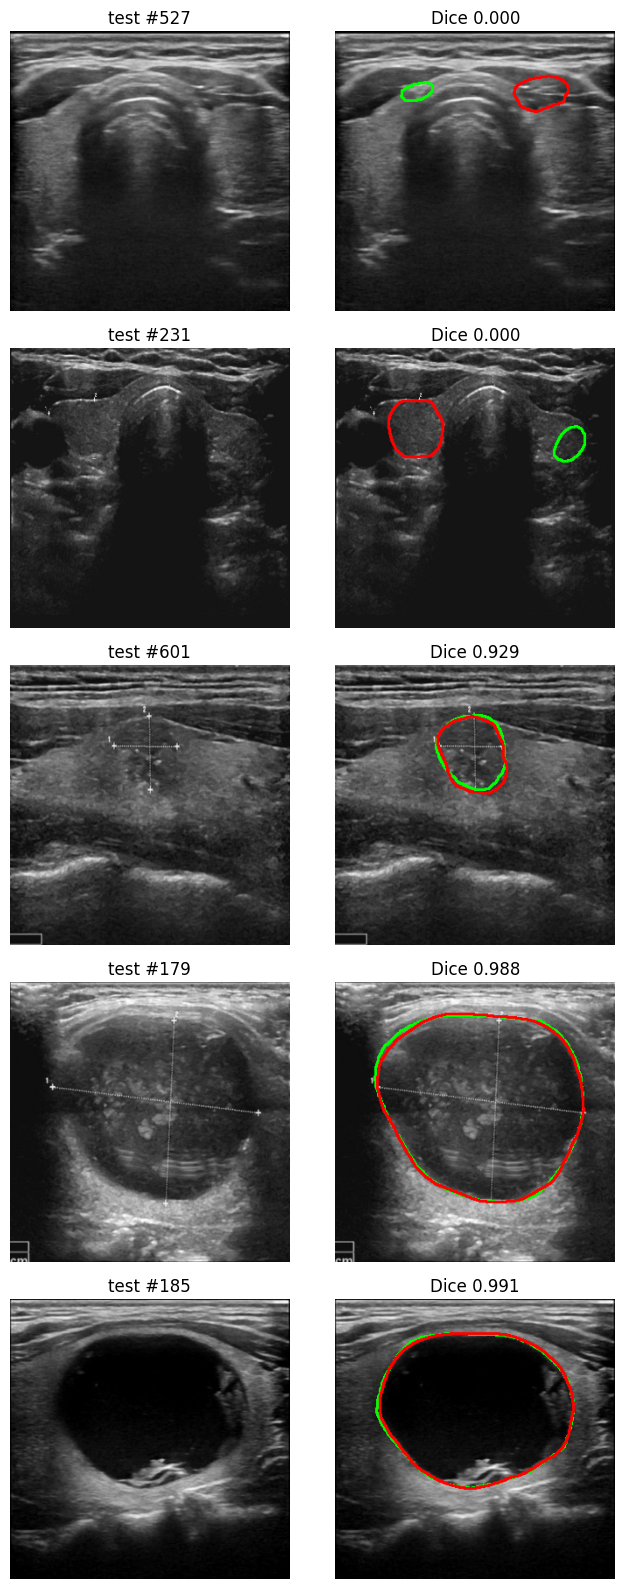

In [9]:
# Cell 9 — FINAL report. The OFFICIAL TN3K test set is scored ONCE, with everything frozen in cells 7-8 (all selections used trainval OOF only).
B_oof = decode(BASE_oof, FINAL_CFG); B_test = decode(BASE_test, FINAL_CFG)
oof_df = full_metrics(B_oof, OOF_MASK); te_df = full_metrics(B_test, TEST_MASK)
METRICS = ["Dice", "IoU", "Precision", "Recall", "Specificity", "Accuracy", "HD95", "ASSD"]


def summarize(df, title):
    rows = []
    for k in METRICS:
        mean, lo, hi = bootstrap_ci(df[k]); rows.append({"Metric": k, "Mean": round(mean, 4), "Std": round(df[k].std(), 4), "95% CI": f"[{lo:.4f}, {hi:.4f}]"})
    print(title); print(pd.DataFrame(rows).to_string(index=False)); return pd.DataFrame(rows)


print("=" * 90)
print(f"A) OUT-OF-FOLD on trainval (n={len(oof_df)}):  Dice {oof_df['Dice'].mean():.4f} | IoU {oof_df['IoU'].mean():.4f} | HD95 {oof_df['HD95'].mean():.1f}  "
      f"(used for model selection - NOT the headline)")
print("=" * 90)
tab_grid = summarize(te_df, f"B) OFFICIAL TEST (n={len(te_df)}), scored on the {S0}x{S0} grid - HD95/ASSD in grid pixels")


# --- native-resolution evaluation: the decoded mask is up-sampled to each image's original size and compared with the ORIGINAL mask ---
def to_native(B, df):
    out = []
    for b, k in zip(B, df["img"]):
        H, W = RAW[k][1].shape
        out.append(cv2.resize(b.astype(np.float32), (W, H), interpolation=cv2.INTER_LINEAR) > 0.5)
    return out


nat_pred = to_native(B_test, test_df); nat_gt = [RAW[k][1] > 127 for k in test_df["img"]]
nat_df = pd.concat([full_metrics(p[None], g[None]) for p, g in zip(nat_pred, nat_gt)], ignore_index=True)
tab_nat = summarize(nat_df, f"\nC) OFFICIAL TEST, NATIVE image resolution (HD95/ASSD in original pixels)")
te_df["size_q"] = test_df["strat"].values
print("\nD) By nodule size on the test set (quartiles of nodule area; 0 = smallest, 3 = largest):")
print(te_df.groupby("size_q")[["Dice", "IoU", "HD95"]].agg(["mean", "count"]).round(4).to_string())
print(f"\nImages with Dice < 0.5: {(te_df['Dice'] < 0.5).sum()} / {len(te_df)}   |   median Dice {te_df['Dice'].median():.4f}")

# --- published results on the SAME official test set, AS REPORTED by the cited papers (protocols, training data and resolution differ) ---
PUBLISHED = {   # name: (Dice %, IoU %)
    "TRFE (Gong et al., 2021)": (81.19, 68.33),
    "TRFE+ (Gong et al.)": (83.30, 71.38),
    "SegFormer (as reported in EffiViT3+ paper)": (82.34, 70.28),
    "DDTransUNet (Zhang et al., 2024)": (82.31, 73.82),
    "GSE-Nets (Li et al., 2025)": (81.97, 72.24),
    "STU3Net (Deng et al., 2024)": (83.68, 74.16),
    "Improved V-Net (Yetginler & Atacak, 2025)": (83.88, 75.50),
    "U-Net + ResNet encoder (Prochazka & Zeman, 2025)": (84.24, 75.48),
    "EffiViT3+ (2025)": (87.16, 77.43),
    "BFG&MSF-Net (Liu et al., 2024)": (87.26, 76.34),
}
ours = {"OURS - grid 320 (cell 9-B)": (100 * te_df["Dice"].mean(), 100 * te_df["IoU"].mean()),
        "OURS - native resolution (cell 9-C)": (100 * nat_df["Dice"].mean(), 100 * nat_df["IoU"].mean())}
cmp_df = pd.DataFrame({**PUBLISHED, **ours}, index=["Dice %", "IoU %"]).T.sort_values("Dice %", ascending=False)
print("\nE) Comparison with published TN3K results (numbers copied from the cited papers; protocols differ - differences below ~1 point are not meaningful):")
print(cmp_df.round(2).to_string())
rank = int((cmp_df["Dice %"] > ours["OURS - native resolution (cell 9-C)"][0]).sum()) + 1
print(f"\nOurs (native) ranks #{rank} of {len(cmp_df)} on Dice in this table. Beating a published number only counts if the split, training data and metric match - state this explicitly in the paper.")
print("Do not tune anything on the test set. If you re-run with different settings, the test set has been seen again - say so.")

json.dump({"test_grid": {k: float(te_df[k].mean()) for k in METRICS}, "test_native": {k: float(nat_df[k].mean()) for k in METRICS},
           "oof": {k: float(oof_df[k].mean()) for k in METRICS}, "weights": W2, "use_qif": bool(USE_QIF), "preset": PRESET,
           "decoder": {k: v for k, v in FINAL_CFG.items()}, "specs": [{k: (list(v) if isinstance(v, tuple) else v) for k, v in s_.items()} for s_ in SPECS]},
          open(os.path.join(CFG["out_dir"], "results.json"), "w"), indent=2, default=float)
te_df.assign(img=test_df["img"].values).to_csv(os.path.join(CFG["out_dir"], "test_per_image_grid.csv"), index=False)
nat_df.assign(img=test_df["img"].values).to_csv(os.path.join(CFG["out_dir"], "test_per_image_native.csv"), index=False)
np.savez_compressed(os.path.join(CFG["out_dir"], "final_test_masks.npz"), masks=B_test.astype(np.uint8), probs=BASE_test.astype(np.float16))

# qualitative: worst / median / best test cases   (green = ground truth, red = prediction)
order = np.argsort(te_df["Dice"].values); pick = list(order[:2]) + [order[len(order) // 2]] + list(order[-2:])
fig, ax = plt.subplots(len(pick), 2, figsize=(7, 3.2 * len(pick)))
for r, i in enumerate(pick):
    img = cv2.resize(RAW[test_df["img"][i]][0], (S0, S0)); o = img.copy()
    for m_, col in ((TEST_MASK[i], (0, 255, 0)), (B_test[i], (255, 0, 0))):
        cs, _ = cv2.findContours(m_.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(o, cs, -1, col, 2)
    ax[r, 0].imshow(img); ax[r, 0].set_title(f"test #{i}"); ax[r, 1].imshow(o); ax[r, 1].set_title(f"Dice {te_df['Dice'][i]:.3f}")
    for a in ax[r]:
        a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "qualitative.png"), dpi=200); plt.show()

In [10]:
# Cell 10 — FAILURE ANATOMY + OOF-gated repairs.
# Run AFTER cell 9 (needs BANK, BASE_oof/BASE_test, FINAL_CFG, decode, ... in memory; if the kernel restarted, re-run cells 1,2,4-6 -
# finished folds load from outputs_v2/probs in seconds - then cells 7-8).
# All decisions use OOF only; a repair is adopted ONLY if its paired-bootstrap 95% CI on OOF Dice is entirely > 0.
from scipy import ndimage as ndi

MEMBERS = [n for n in BANK if n != "S2_roi"]                       # independent stage-1 models
B_base_oof = decode(BASE_oof, FINAL_CFG)
d_base, i_base = fast_metrics(B_base_oof, OOF_MASK)


def agreement(i, key="oof"):
    ms = [BANK[n][key][i] > 0.5 for n in MEMBERS]; v = []
    for a in range(len(ms)):
        for b in range(a + 1, len(ms)):
            u = (ms[a] | ms[b]).sum(); v.append((ms[a] & ms[b]).sum() / u if u else 1.0)
    return float(np.mean(v))


def failure_kind(pa, ga, inter):
    if pa == 0: return "empty prediction"
    if inter == 0: return "wrong place (0 overlap)"
    if pa > 2 * ga: return "over-segmentation"
    if pa < 0.5 * ga: return "under-segmentation"
    return "misaligned"


rows = []
for i in range(len(d_base)):
    pa, ga = int(B_base_oof[i].sum()), int(OOF_MASK[i].sum()); inter = int((B_base_oof[i] & OOF_MASK[i].astype(bool)).sum())
    rows.append(dict(dice=d_base[i], kind=failure_kind(pa, ga, inter) if d_base[i] < 0.5 else "ok", gt_frac=ga / OOF_MASK[i].size,
                     n_gt_obj=ndlabel(OOF_MASK[i])[1], mal=bool(IS_MAL_CV[i]), agree=agreement(i)))
an = pd.DataFrame(rows); med_ok = an.loc[an.kind == "ok", "dice"].median()
print(f"OOF: mean Dice {an.dice.mean():.4f} | median {an.dice.median():.4f} | images with Dice<0.5: {(an.kind != 'ok').sum()} / {len(an)}")
print(f"mean Dice of the {int((an.kind == 'ok').sum())} non-failures: {an.loc[an.kind == 'ok', 'dice'].mean():.4f}   <- boundary quality is NOT the bottleneck\n")
fa = an[an.kind != "ok"]
tab = fa.groupby("kind").agg(n=("dice", "size"), mean_dice=("dice", "mean"), gt_area_pct=("gt_frac", lambda s: 100 * s.mean()),
                              multi_lesion=("n_gt_obj", lambda s: (s > 1).mean()), model_agreement=("agree", "mean"))
tab["mean_Dice_gain_if_fixed"] = [float((np.maximum(0, med_ok - fa.loc[fa.kind == k, "dice"])).sum() / len(an)) for k in tab.index]
print(tab.round(3).to_string())
print(f"\nmodel_agreement = mean pairwise IoU between the independent models' masks. For 'wrong place' failures a HIGH value means all models")
print(f"confidently agree with each other against the label (label ambiguity -> not fixable by any model); a LOW value means they disagree (fixable).")
print(f"agreement on good images: {an.loc[an.kind == 'ok', 'agree'].mean():.3f} | on failures: {fa.agree.mean():.3f}")
print(f"UPPER BOUND if EVERY failure were repaired to the median good-image Dice: {an.dice.mean() + tab.mean_Dice_gain_if_fixed.sum():.4f}\n")


# ---------------- repairs ----------------
def dec_components(P, thr=0.5, score="area", keep=0.0, rescue=None, min_frac=0.0015):
    out = []
    for p in P.astype(np.float32):
        b = p > thr
        if rescue is not None and b.sum() < 0.0005 * b.size and p.max() > rescue[1]:
            b = p >= rescue[0] * p.max()                              # empty/tiny prediction -> relative threshold from the peak
        b = binary_fill_holes(b); lab, n = ndlabel(b)
        if n > 1:
            idx = np.arange(1, n + 1); area = ndi.sum(np.ones_like(p), lab, idx)
            s = {"area": area, "mass": ndi.sum(p, lab, idx), "peakarea": ndi.maximum(p, lab, idx) * np.sqrt(area)}[score]
            b = np.isin(lab, idx[s >= keep * s.max()])
        ms = int(min_frac * b.size)
        out.append(_rm_small(b, ms) if ms > 0 and b.any() else b)
    return np.stack(out)


def dec_vote(key, k):
    return sum((BANK[n][key] > 0.5).astype(np.uint8) for n in MEMBERS) >= k


def dec_medoid(key):                                                 # per image: the model whose mask agrees most with the others
    out = []
    for i in range(len(BANK[MEMBERS[0]][key])):
        ms = [BANK[n][key][i] > 0.5 for n in MEMBERS]
        sc = [np.mean([(a & b).sum() / max(1, (a | b).sum()) for b in ms if b is not a]) for a in ms]
        out.append(ms[int(np.argmax(sc))])
    return np.stack(out)


def paired_ci(new, base, n=2000, seed=0):
    d = new - base; rng = np.random.default_rng(seed)
    b = [rng.choice(d, len(d), replace=True).mean() for _ in range(n)]
    return float(d.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


cands = {}
for score in ("area", "mass", "peakarea"):
    for keep in (1.0, 0.4, 0.0):
        for resc in (None, (0.5, 0.15), (0.7, 0.25)):
            cands[f"components score={score} keep={keep} rescue={resc}"] = ("comp", dict(score=score, keep=keep, rescue=resc))
for k in range(1, len(MEMBERS) + 1):
    cands[f"majority vote >= {k}/{len(MEMBERS)}"] = ("vote", k)
cands["per-image medoid model"] = ("medoid", None)


def run(c, key, P):
    kind, a = c
    if kind == "comp": return dec_components(P, **a)
    if kind == "vote": return np.stack([postproc(b) for b in dec_vote(key, a)])
    return np.stack([postproc(b) for b in dec_medoid(key)])


res = []
for nm, c in cands.items():
    d, _ = fast_metrics(run(c, "oof", BASE_oof), OOF_MASK); res.append((d.mean(), nm, d))
res.sort(key=lambda r: -r[0])
print("best repairs on OOF (baseline %.4f):" % d_base.mean())
for dm, nm, _ in res[:6]:
    print(f"  {dm:.4f}  {nm}")
dm, nm, dbest = res[0]; delta, lo, hi = paired_ci(dbest, d_base)
print(f"\nbest candidate: '{nm}'  paired OOF gain {delta:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")
ADOPT = lo > 0
print("ADOPTED (CI entirely above 0)" if ADOPT else "NOT adopted: the gain is within noise -> keep the frozen decoder from cell 8")

B_fin = run(cands[nm], "test", BASE_test) if ADOPT else decode(BASE_test, FINAL_CFG)
te2 = full_metrics(B_fin, TEST_MASK)
print(f"\nHOLD-OUT TEST with this frozen choice (second and last look): Dice {te2.Dice.mean():.4f} | IoU {te2.IoU.mean():.4f} | "
      f"HD95 {te2.HD95.mean():.1f} | Dice<0.5: {(te2.Dice < 0.5).sum()}/{len(te2)}")

OOF: mean Dice 0.8501 | median 0.9104 | images with Dice<0.5: 147 / 2879
mean Dice of the 2732 non-failures: 0.8811   <- boundary quality is NOT the bottleneck

                          n  mean_dice  gt_area_pct  multi_lesion  model_agreement  mean_Dice_gain_if_fixed
kind                                                                                                       
misaligned               10      0.287        5.844         0.300            0.470                    0.002
over-segmentation        60      0.316        3.047         0.067            0.631                    0.012
under-segmentation       61      0.303       17.006         0.295            0.647                    0.013
wrong place (0 overlap)  16      0.000        3.281         0.000            0.430                    0.005

model_agreement = mean pairwise IoU between the independent models' masks. For 'wrong place' failures a HIGH value means all models
confidently agree with each other against the label (label

In [11]:
# Cell 11 — ORACLE DIAGNOSTIC. *** NOT A RESULT - do not report the oracle column. ***
# Re-creates the per-image "pick the best threshold using the ground-truth mask" trick used in some published pipelines, but on
# strictly held-out (OOF) predictions, and prints it next to the honest number so you can see how much of a "0.91" is the answer key.
THS = [0.25, 0.30, 0.35, 0.38, 0.42, 0.45]
Dg = np.zeros((len(OOF_MASK), len(THS))); Ig = np.zeros_like(Dg)
for j, th in enumerate(THS):
    Dg[:, j], Ig[:, j] = fast_metrics(np.stack([postproc(b) for b in (BASE_oof > th)]), OOF_MASK)
jb = int(Dg.mean(0).argmax()); pick = Dg.argmax(1); ar = np.arange(len(Dg))
print("=" * 74)
print(f"{'':44}{'Dice':>10}{'IoU':>10}")
print(f"{'HONEST  one global threshold (' + str(THS[jb]) + ')':44}{Dg[:, jb].mean():>10.4f}{Ig[:, jb].mean():>10.4f}")
print(f"{'ORACLE  best threshold per image, chosen by GT':44}{Dg.max(1).mean():>10.4f}{Ig[ar, pick].mean():>10.4f}   <- not reportable")
print("=" * 74)
print(f"The label-peeking trick alone adds {Dg.max(1).mean() - Dg[:, jb].mean():+.4f} Dice here (held-out data, no leakage).")
print("A real, reportable per-image threshold is what cell 8's expected-Dice decoding (EDOD) tries - it never looks at the label.")

                                                  Dice       IoU
HONEST  one global threshold (0.45)             0.8490    0.7657
ORACLE  best threshold per image, chosen by GT    0.8603    0.7803   <- not reportable
The label-peeking trick alone adds +0.0113 Dice here (held-out data, no leakage).
A real, reportable per-image threshold is what cell 8's expected-Dice decoding (EDOD) tries - it never looks at the label.


In [12]:
# Cell 12 — ABLATION + STATISTICS (what a reviewer will ask for). Trains ONE extra model, kept OUT of the ensemble (BANK untouched,
# so cells 8-10 numbers do not change).  G = the first (QKA) model with the quantum-kernel-attention switched OFF (same backbone, seed, folds, loss).
# Needs CFG-level switch RUN_ABLATION = True in cell 1 (it costs one extra model of GPU time).
from scipy.stats import wilcoxon

if not RUN_ABLATION:
    print("Ablation skipped (set RUN_ABLATION = True in cell 1 to train the no-QKA model and get the paired tests).")
else:
    from scipy.stats import wilcoxon

    C_NAME = SPECS[0]["name"]
    assert SPECS[0]["qka"], "SPECS[0] must be a QKA model for this ablation"
    G_NAME = C_NAME.replace("QKA", "noQKA") if "QKA" in C_NAME else C_NAME + "_noQKA"
    ABL_SPECS = [{**SPECS[0], "name": G_NAME, "qka": False, "tta_ablation": True, "extra": False}]
    if CFG["FAST"]:
        for s_ in ABL_SPECS: s_.update(epochs=2, folds=2, size=128, sam_rho=0.0)
    ABL = {s_["name"]: run_cv(s_) for s_ in ABL_SPECS}


    def paired_report(title, new, base, n_boot=5000, seed=0):
        """new/base: per-image Dice arrays of the SAME images. Paired bootstrap CI of the mean difference + Wilcoxon signed-rank test."""
        d = np.asarray(new) - np.asarray(base); rng = np.random.default_rng(seed)
        b = [rng.choice(d, len(d), replace=True).mean() for _ in range(n_boot)]
        try: pv = wilcoxon(d).pvalue
        except ValueError: pv = float("nan")
        verdict = "significant" if (np.percentile(b, 2.5) > 0 or np.percentile(b, 97.5) < 0) else "NOT significant"
        print(f"{title:<46} {new.mean():.4f} vs {base.mean():.4f} | diff {d.mean():+.4f} 95% CI [{np.percentile(b, 2.5):+.4f}, {np.percentile(b, 97.5):+.4f}] | Wilcoxon p={pv:.3g} | {verdict}")


    dC = fast_metrics(BANK[C_NAME]["oof"] > 0.5, OOF_MASK)[0]
    G = ABL[G_NAME]
    dG = fast_metrics(G["oof"] > 0.5, OOF_MASK)[0]
    dGn = fast_metrics(G["oof_nt"] > 0.5, OOF_MASK)[0]
    print("OOF per-image Dice, n=%d, threshold 0.5, no post-processing\n" % len(dC))
    paired_report("QKA effect   (with QKA  vs  without)", dC, dG)
    paired_report("TTA effect   (TTA  vs  no TTA, no-QKA model)", dG, dGn)
    best_single = max((n for n in BANK if n != "S2_roi"), key=lambda n: fast_metrics(BANK[n]["oof"] > 0.5, OOF_MASK)[0].mean())
    dBest = fast_metrics(BANK[best_single]["oof"] > 0.5, OOF_MASK)[0]
    dEns = fast_metrics(decode(BASE_oof, FINAL_CFG), OOF_MASK)[0]
    paired_report(f"Ensemble vs best single ({best_single[:12]})", dEns, dBest)
    tG = fast_metrics(G["test"] > 0.5, TEST_MASK)[0]; tGn = fast_metrics(G["test_nt"] > 0.5, TEST_MASK)[0]
    tC = fast_metrics(BANK[C_NAME]["test"] > 0.5, TEST_MASK)[0]
    print("\nHold-out test (n=%d, informational - nothing was selected on it):" % len(tC))
    paired_report("QKA effect   (with vs without)", tC, tG); paired_report("TTA effect   (TTA vs no TTA)", tG, tGn)
    print("\nHow to read: if 'QKA effect' is NOT significant, say so in the paper - a rigorous null result on a quantum component is a")
    print("publishable finding; claiming a gain that the paired test does not support is not. Single seed: for a stronger claim repeat with 3 seeds.")

Ablation skipped (set RUN_ABLATION = True in cell 1 to train the no-QKA model and get the paired tests).


In [13]:
# Cell 13 — NEAR-DUPLICATE AUDIT. TN3K has 3,493 images from 2,421 patients (~1.4 images per patient) and the files carry no patient IDs, so images of
# the same nodule can fall in different CV folds (making OOF numbers optimistic). The official test split is the one to report; this cell estimates the risk.
# Run after cell 9 (needs te_df). Uses a 32x32 grayscale Pearson-correlation fingerprint of every image (no model needed).
def fingerprint(img):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    return (g - g.mean()) / (g.std() + 1e-6)


Z_cv = np.stack([fingerprint(RAW[k][0]) for k in cv_df["img"]]); Z_te = np.stack([fingerprint(RAW[k][0]) for k in test_df["img"]])
C_te = Z_te @ Z_cv.T / Z_cv.shape[1]                                     # (98, 549) correlations
nn_te = C_te.max(1)
C_cv = Z_cv @ Z_cv.T / Z_cv.shape[1]; np.fill_diagonal(C_cv, -1); nn_cv = C_cv.max(1)
print("nearest-neighbour correlation of each HOLD-OUT image to the CV pool  /  of each CV image to the rest of the CV pool")
print(f"{'corr >=':>8} {'test imgs':>10} {'CV imgs':>9}")
for t in (0.80, 0.90, 0.95, 0.98):
    print(f"{t:>8.2f} {int((nn_te >= t).sum()):>10d} {int((nn_cv >= t).sum()):>9d}")
for t in (0.90, 0.95):
    keep = nn_te < t
    print(f"\nTest Dice with all {len(keep)}: {te_df['Dice'].mean():.4f} | excluding {int((~keep).sum())} images with a near-twin (corr>={t}) "
          f"in the CV pool: {te_df['Dice'][keep].mean():.4f}")
print("\nIf many images have twins, report the de-duplicated test number too (and say how twins were defined). A large drop = optimistic split.")
print("If you can obtain patient IDs / acquisition metadata, split by patient instead - this is the strongest fix.")

nearest-neighbour correlation of each HOLD-OUT image to the CV pool  /  of each CV image to the rest of the CV pool
 corr >=  test imgs   CV imgs
    0.80        168       843
    0.90          4       107
    0.95          0        36
    0.98          0        22

Test Dice with all 614: 0.8783 | excluding 4 images with a near-twin (corr>=0.9) in the CV pool: 0.8779

Test Dice with all 614: 0.8783 | excluding 0 images with a near-twin (corr>=0.95) in the CV pool: 0.8783

If many images have twins, report the de-duplicated test number too (and say how twins were defined). A large drop = optimistic split.
If you can obtain patient IDs / acquisition metadata, split by patient instead - this is the strongest fix.


In [14]:
# Cell 14 — PAPER ARTIFACTS: LaTeX results table, per-model table, ablation-ready summary, README of exactly what was run.
rows = []
for n in [x for x in BANK if x != "S2_roi"] + ["S2_roi"]:
    d_oof = fast_metrics(BANK[n]["oof"] > 0.5, OOF_MASK); d_te = fast_metrics(BANK[n]["test"] > 0.5, TEST_MASK)
    rows.append({"Model": n, "OOF Dice": d_oof[0].mean(), "OOF IoU": d_oof[1].mean(), "Test Dice": d_te[0].mean(), "Test IoU": d_te[1].mean()})
rows.append({"Model": "FINAL ensemble (frozen pipeline)", "OOF Dice": oof_df["Dice"].mean(), "OOF IoU": oof_df["IoU"].mean(),
             "Test Dice": te_df["Dice"].mean(), "Test IoU": te_df["IoU"].mean()})
models_df = pd.DataFrame(rows).round(4); print("Per-model results (threshold 0.5, no post-processing, except the last row):\n"); print(models_df.to_string(index=False))
models_df.to_csv(os.path.join(CFG["out_dir"], "table_models.csv"), index=False)


def latex_table(df, caption, label):
    cols = " & ".join(df.columns) + r" \\"
    body = "\n".join(" & ".join(str(v).replace("_", r"\_").replace("&", r"\&") for v in r) + r" \\" for r in df.itertuples(index=False))
    return ("\\begin{table}[t]\n\\centering\n\\caption{" + caption + "}\n\\label{" + label + "}\n\\begin{tabular}{l" + "c" * (len(df.columns) - 1) + "}\n\\hline\n"
            + cols + "\n\\hline\n" + body + "\n\\hline\n\\end{tabular}\n\\end{table}\n")


open(os.path.join(CFG["out_dir"], "table_models.tex"), "w").write(latex_table(models_df, "Individual members and the final ensemble on TN3K (out-of-fold on trainval; official test).", "tab:models"))
cmp_tex = cmp_df.round(2).reset_index().rename(columns={"index": "Method"})
open(os.path.join(CFG["out_dir"], "table_vs_published.tex"), "w").write(
    latex_table(cmp_tex, "Comparison with published TN3K results as reported by the cited works (protocols differ; see text).", "tab:sota"))
open(os.path.join(CFG["out_dir"], "README_run.txt"), "w").write(
    f"preset={PRESET}; seed={CFG['seed']}; S0={S0}\nmodels={[s_['name'] for s_ in SPECS]}\nstage2={STAGE2['name']}\n"
    f"final decoder={FINAL_CFG}\nweights={W2}\nQIF used={USE_QIF}\nCV pool={len(cv_df)} trainval images; test={len(test_df)} official test images (scored once)\n"
    "All ensemble weights, thresholds, annealing parameters, temperature and block choices were selected on trainval out-of-fold predictions only.\n")
print("\nwritten to", CFG["out_dir"], ":", sorted(os.listdir(CFG["out_dir"])))
print("\nWhat to put in the paper: (1) the OOF + official-test tables with CIs, (2) the ablation from cell 12 (RUN_ABLATION=True) incl. paired tests,")
print("(3) the failure-anatomy table from cell 10, (4) the oracle-vs-honest gap from cell 11 as a methodological note, (5) the duplicate audit from cell 13.")

Per-model results (threshold 0.5, no post-processing, except the last row):

                           Model  OOF Dice  OOF IoU  Test Dice  Test IoU
                   C_QKA_cnxs352    0.8447   0.7601     0.8727    0.7965
                 D_FPN_effv2_352    0.8313   0.7411     0.8547    0.7737
                E_QKA_pvt2b2_352    0.8384   0.7498     0.8692    0.7913
                          S2_roi    0.8477   0.7644     0.8731    0.7987
FINAL ensemble (frozen pipeline)    0.8501   0.7674     0.8783    0.8053

written to outputs_tn3k : ['README_run.txt', 'final_test_masks.npz', 'probs_TN3K_s42', 'qualitative.png', 'results.json', 'table_models.csv', 'table_models.tex', 'table_vs_published.tex', 'test_per_image_grid.csv', 'test_per_image_native.csv']

What to put in the paper: (1) the OOF + official-test tables with CIs, (2) the ablation from cell 12 (RUN_ABLATION=True) incl. paired tests,
(3) the failure-anatomy table from cell 10, (4) the oracle-vs-honest gap from cell 11 as a methodo